In [ ]:
# Chess Game Analysis with UNIFIED PCA per Color
# Analisi con 2 PCA: una per Bianco, una per Nero (poi separazione per risultato)

import io, gzip
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix
from tqdm import tqdm
import chess
import chess.pgn

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)

# ===== CONFIGURATION =====
print("📋 Configuration")
print("="*60)

INPUT_PATH = r"C:\Users\Luca\OneDrive - Università Commerciale Luigi Bocconi\Desktop\fishtest_2018"
MAX_GAMES = 10000
MIN_MOVES = 10

print(f"Input path: {INPUT_PATH}")
print(f"Max games: {MAX_GAMES if MAX_GAMES else 'ALL'}")
print(f"Min moves: {MIN_MOVES}\n")

# ===== CONSTANTS =====
PIECE_VALUES = {
    chess.PAWN: 100, chess.KNIGHT: 320, chess.BISHOP: 330,
    chess.ROOK: 500, chess.QUEEN: 900, chess.KING: 20000
}

CENTER_SQ = [chess.D4, chess.E4, chess.D5, chess.E5]
EXT_CENTER = [chess.C3, chess.C4, chess.C5, chess.C6, chess.D3, chess.E3,
              chess.D6, chess.E6, chess.F3, chess.F4, chess.F5, chess.F6]

# ===== UTILITY FUNCTIONS =====
def _human_size(num_bytes: int) -> str:
    for unit in ["B", "KB", "MB", "GB", "TB"]:
        if num_bytes < 1024.0:
            return f"{num_bytes:3.1f} {unit}"
        num_bytes /= 1024.0
    return f"{num_bytes:.1f} PB"

def _is_pgn_file(path: Path) -> bool:
    if not path.is_file():
        return False
    name = path.name.lower()
    return name.endswith(".pgn") or name.endswith(".pgn.gz")

def _open_pgn(path: Path):
    if path.suffix.lower() == ".gz" or path.name.lower().endswith(".pgn.gz"):
        return gzip.open(path, "rt", encoding="utf-8", errors="ignore")
    return open(path, "r", encoding="utf-8", errors="ignore")

def iter_games_from_path(path: Path, limit: int = None):
    count = 0
    if path.is_file():
        if not _is_pgn_file(path):
            raise ValueError(f"File is not a PGN: {path}")
        with _open_pgn(path) as f:
            while True:
                if limit is not None and count >= limit:
                    return
                try:
                    game = chess.pgn.read_game(f)
                    if game is None:
                        break
                    yield game
                    count += 1
                except Exception as e:
                    print(f"⚠️ Error reading game {count+1}: {e}")
                    continue
    else:
        files = sorted(list(path.rglob("*.pgn")) + list(path.rglob("*.pgn.gz")))
        for fp in files:
            with _open_pgn(fp) as f:
                while True:
                    if limit is not None and count >= limit:
                        return
                    try:
                        game = chess.pgn.read_game(f)
                        if game is None:
                            break
                        yield game
                        count += 1
                    except Exception as e:
                        print(f"⚠️ Error in {fp.name}: {e}")
                        continue

# Validate path
p = Path(INPUT_PATH)
if not p.exists():
    raise FileNotFoundError(f"❌ Path not found: {INPUT_PATH}")

if p.is_file():
    if not _is_pgn_file(p):
        raise ValueError(f"❌ Not a PGN file: {p}")
    size = p.stat().st_size
    print(f"✅ File found! Size: {_human_size(size)}\n")
else:
    pgn_files = list(p.rglob("*.pgn")) + list(p.rglob("*.pgn.gz"))
    if not pgn_files:
        raise FileNotFoundError(f"❌ No PGN files in {INPUT_PATH}")
    total_bytes = sum(fp.stat().st_size for fp in pgn_files)
    print(f"✅ Directory found!")
    print(f"   • PGN files: {len(pgn_files)}")
    print(f"   • Total size: {_human_size(total_bytes)}\n")

# ===== FEATURE EXTRACTION =====
print("🔧 Loading feature extraction functions...")

def material_eval(b, perspective_color):
    """Material balance from perspective_color's viewpoint"""
    mat = sum(PIECE_VALUES[pt] * (len(b.pieces(pt, chess.WHITE)) -
               len(b.pieces(pt, chess.BLACK))) for pt in PIECE_VALUES)
    return mat if perspective_color == chess.WHITE else -mat

def piece_counts(b, perspective_color):
    """Piece count difference from perspective"""
    diff = 1 if perspective_color == chess.WHITE else -1
    return {f"cnt_{chess.piece_name(pt)}": diff * (len(b.pieces(pt, chess.WHITE)) -
            len(b.pieces(pt, chess.BLACK)))
            for pt in [chess.PAWN, chess.KNIGHT, chess.BISHOP, chess.ROOK, chess.QUEEN]}

def mobility_stats(b, color):
    """Mobility, captures, checks for given color"""
    tmp = b.copy(stack=False)
    tmp.turn = color
    moves = list(tmp.legal_moves)
    return (len(moves),
            sum(1 for m in moves if tmp.is_capture(m)),
            sum(1 for m in moves if tmp.gives_check(m)))

def attack_overlap(b):
    """Squares attacked by both colors"""
    return sum(1 for sq in chess.SQUARES 
               if b.attackers(chess.WHITE, sq) and b.attackers(chess.BLACK, sq))

def hanging_pieces(b, perspective_color):
    """Undefended pieces (positive = advantage for perspective_color)"""
    def count(color):
        return sum(1 for sq in chess.SquareSet(b.occupied_co[color])
                   if b.attackers(not color, sq) and not b.attackers(color, sq))
    diff = count(not perspective_color) - count(perspective_color)
    return diff

def center_control(b, perspective_color):
    """Center control from perspective"""
    def ctrl(c, sqs): 
        return sum(1 for sq in sqs if b.attackers(c, sq))
    
    opp = not perspective_color
    core = ctrl(perspective_color, CENTER_SQ) - ctrl(opp, CENTER_SQ)
    ext = ctrl(perspective_color, EXT_CENTER) - ctrl(opp, EXT_CENTER)
    return core, ext

def king_safety(b, perspective_color):
    """King safety difference (positive = advantage)"""
    def safety(c):
        ksq = b.king(c)
        if ksq is None: 
            return 0
        kf, kr = chess.square_file(ksq), chess.square_rank(ksq)
        ring = [chess.square(kf+df, kr+dr) for df in [-1,0,1] for dr in [-1,0,1]
                if (df or dr) and 0<=kf+df<=7 and 0<=kr+dr<=7]
        attacks = sum(1 for sq in ring if b.attackers(not c, sq))
        shield = sum(1 for fo in [-1,0,1]
                     if 0<=kf+fo<=7 and 0<=kr+(1 if c==chess.WHITE else -1)<=7
                     and b.piece_type_at(chess.square(kf+fo, kr+(1 if c==chess.WHITE else -1)))==chess.PAWN
                     and b.color_at(chess.square(kf+fo, kr+(1 if c==chess.WHITE else -1)))==c)
        return shield - attacks
    
    return safety(perspective_color) - safety(not perspective_color)

def pawn_structure(b, perspective_color):
    """Pawn structure from perspective"""
    def feat(c):
        pawns = b.pieces(chess.PAWN, c)
        files = [chess.square_file(sq) for sq in pawns]
        doubled = sum(max(0, files.count(f)-1) for f in range(8))
        isolated = sum(1 for f in range(8) if files.count(f)>0 and
                       files.count(f-1)==0 and files.count(f+1)==0)
        passed = 0
        for sq in pawns:
            sq_file = chess.square_file(sq)
            ahead_range = range(sq+8, 64, 8) if c == chess.WHITE else range(sq-8, -1, -8)
            blocked = False
            for a in ahead_range:
                a_file = chess.square_file(a)
                if a_file in [sq_file-1, sq_file, sq_file+1]:
                    if b.piece_type_at(a) == chess.PAWN and b.color_at(a) != c:
                        blocked = True
                        break
            if not blocked:
                passed += 1
        return doubled, isolated, passed

    opp = not perspective_color
    dP, iP, pP = feat(perspective_color)
    dO, iO, pO = feat(opp)
    return (dP-dO, iP-iO, pP-pO)

print("✅ Functions loaded\n")

# ===== FEATURE EXTRACTION PER GAME =====
def extract_features_both_colors(game):
    """Extract features for BOTH White and Black moves"""
    board = game.board()
    white_rows = []
    black_rows = []
    ply = 0

    try:
        for move in game.mainline_moves():
            board.push(move)
            ply += 1

            # Determine who just moved
            player_color = chess.WHITE if board.turn == chess.BLACK else chess.BLACK
            
            # Extract features from player's perspective
            mob, cap, chk = mobility_stats(board, player_color)
            mat = material_eval(board, player_color)
            counts = piece_counts(board, player_color)
            core, ext = center_control(board, player_color)
            pawn_d, pawn_i, pawn_p = pawn_structure(board, player_color)

            row = {
                'ply': ply,
                'material': mat,
                'mobility': mob,
                'captures_avail': cap,
                'checks_avail': chk,
                'attack_overlap': attack_overlap(board),
                'hanging_diff': hanging_pieces(board, player_color),
                'center_core': core,
                'center_ext': ext,
                'king_safety_diff': king_safety(board, player_color),
                'pawns_doubled_diff': pawn_d,
                'pawns_isolated_diff': pawn_i,
                'pawns_passed_diff': pawn_p,
                **counts
            }

            if player_color == chess.WHITE:
                row['move_num'] = len(white_rows) + 1
                white_rows.append(row)
            else:
                row['move_num'] = len(black_rows) + 1
                black_rows.append(row)

    except Exception as e:
        return None, None

    if len(white_rows) < MIN_MOVES or len(black_rows) < MIN_MOVES:
        return None, None

    # Get result
    result = game.headers.get('Result', '*')
    if result not in ['1-0', '0-1', '1/2-1/2']:
        return None, None

    # Create DataFrames
    df_white = pd.DataFrame(white_rows)
    df_black = pd.DataFrame(black_rows)

    # Add result from each perspective
    if result == '1-0':
        df_white['result'] = 'W'
        df_black['result'] = 'L'
    elif result == '0-1':
        df_white['result'] = 'L'
        df_black['result'] = 'W'
    else:
        df_white['result'] = 'D'
        df_black['result'] = 'D'

    # Add delta mobility
    df_white['delta_mobility'] = df_white['mobility'].diff().fillna(0)
    df_black['delta_mobility'] = df_black['mobility'].diff().fillna(0)

    return df_white, df_black

# ===== PROCESS GAMES =====
print("="*60)
print("🔄 PROCESSING GAMES (BOTH COLORS)")
print("="*60)

white_games = []
black_games = []
parsed_count = 0
skipped_count = 0

game_generator = iter_games_from_path(p, limit=MAX_GAMES)

for game in tqdm(game_generator, desc="Processing", total=MAX_GAMES):
    parsed_count += 1
    
    df_w, df_b = extract_features_both_colors(game)
    if df_w is not None and df_b is not None:
        white_games.append(df_w)
        black_games.append(df_b)
    else:
        skipped_count += 1

if not white_games:
    raise ValueError("❌ No valid games found!")

print(f"\n✅ {len(white_games)} games processed")
print(f"   ({skipped_count} skipped)\n")

# ===== CONCATENATE DATA =====
print("🧹 Preparing data...")

white_data = pd.concat(white_games, keys=range(len(white_games)), names=['game_id', 'idx'])
white_data = white_data.reset_index(level=0)
white_data['color'] = 'white'

black_data = pd.concat(black_games, keys=range(len(black_games)), names=['game_id', 'idx'])
black_data = black_data.reset_index(level=0)
black_data['color'] = 'black'

# Define features
FEATURES = [c for c in white_data.select_dtypes(include=[np.number]).columns
            if c not in ['ply', 'move_num', 'game_id']]

# Clean data
for df in [white_data, black_data]:
    df[FEATURES] = df[FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)

print(f"✅ Features: {len(FEATURES)}")
print(f"   White observations: {len(white_data)}")
print(f"   Black observations: {len(black_data)}\n")

# ===== 2 UNIFIED PCAs (One per Color) =====
print("="*60)
print("🎯 COMPUTING 2 UNIFIED PCAs (White & Black)")
print("="*60)

def compute_unified_pca(data, color_name):
    """
    Compute ONE PCA using ALL observations for a color,
    then project and separate by result afterwards
    """
    print(f"\n📊 {color_name} Unified PCA...")
    
    # Fit PCA on ALL data for this color
    X = data[FEATURES].values
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    pca = PCA(n_components=2, random_state=42)
    components = pca.fit_transform(X_scaled)
    
    # Add PCA coordinates to the full dataset
    data = data.copy()
    data['PCA1'] = components[:, 0]
    data['PCA2'] = components[:, 1]
    
    # Compute loadings
    loadings = pd.DataFrame(
        pca.components_.T,
        index=FEATURES,
        columns=['PCA1', 'PCA2']
    )
    
    # NOW split by result (after projection)
    subset_win = data[data['result'] == 'W'].copy()
    subset_draw = data[data['result'] == 'D'].copy()
    subset_loss = data[data['result'] == 'L'].copy()
    
    return {
        'pca': pca,
        'loadings': loadings,
        'scaler': scaler,
        'win': subset_win if len(subset_win) >= 50 else None,
        'draw': subset_draw if len(subset_draw) >= 50 else None,
        'loss': subset_loss if len(subset_loss) >= 50 else None
    }

# Compute 2 unified PCAs
white_unified = compute_unified_pca(white_data, "White")
black_unified = compute_unified_pca(black_data, "Black")

# Extract subsets for convenience
white_win = white_unified['win']
white_draw = white_unified['draw']
white_loss = white_unified['loss']
pca_white = white_unified['pca']
load_white = white_unified['loadings']

black_win = black_unified['win']
black_draw = black_unified['draw']
black_loss = black_unified['loss']
pca_black = black_unified['pca']
load_black = black_unified['loadings']

# Print variance explained
print("\n" + "="*60)
print("📈 VARIANCE EXPLAINED")
print("="*60)
var1_w, var2_w = pca_white.explained_variance_ratio_
var1_b, var2_b = pca_black.explained_variance_ratio_
print(f"White (unified): PCA1={var1_w:.2%}, PCA2={var2_w:.2%}, Total={var1_w+var2_w:.2%}")
print(f"Black (unified): PCA1={var1_b:.2%}, PCA2={var2_b:.2%}, Total={var1_b+var2_b:.2%}")

# ===== TRAJECTORY COMPUTATION =====
print("\n📊 Computing average trajectories...")

max_moves = 50

def compute_trajectory(subset):
    """Compute average trajectory for a subset"""
    if subset is None or len(subset) == 0:
        return None, None
    
    subset = subset[subset['move_num'] <= max_moves].copy()
    avg = subset.groupby('move_num')[['PCA1', 'PCA2']].mean()
    std = subset.groupby('move_num')[['PCA1', 'PCA2']].std()
    n = subset.groupby('move_num').size().clip(lower=1)
    se = std.div(np.sqrt(n), axis=0)
    
    return avg, se

traj_ww, se_ww = compute_trajectory(white_win)
traj_wd, se_wd = compute_trajectory(white_draw)
traj_wl, se_wl = compute_trajectory(white_loss)
traj_bw, se_bw = compute_trajectory(black_win)
traj_bd, se_bd = compute_trajectory(black_draw)
traj_bl, se_bl = compute_trajectory(black_loss)

# ===== MAIN VISUALIZATION =====
print("📈 Creating visualizations...\n")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Unified PCA Trajectories: White vs Black, Win/Draw/Loss', 
             fontsize=16, fontweight='bold', y=0.995)

# Plot 1: White PCA1
ax = axes[0, 0]
if traj_ww is not None:
    x = traj_ww.index
    ax.plot(x, traj_ww['PCA1'], color='green', linewidth=2.5, label='White Win', alpha=0.9)
    ax.fill_between(x, traj_ww['PCA1']-se_ww['PCA1'], traj_ww['PCA1']+se_ww['PCA1'],
                     color='green', alpha=0.15)
if traj_wd is not None:
    x = traj_wd.index
    ax.plot(x, traj_wd['PCA1'], color='gray', linewidth=2.5, label='White Draw', alpha=0.9)
    ax.fill_between(x, traj_wd['PCA1']-se_wd['PCA1'], traj_wd['PCA1']+se_wd['PCA1'],
                     color='gray', alpha=0.15)
if traj_wl is not None:
    x = traj_wl.index
    ax.plot(x, traj_wl['PCA1'], color='red', linewidth=2.5, label='White Loss', alpha=0.9)
    ax.fill_between(x, traj_wl['PCA1']-se_wl['PCA1'], traj_wl['PCA1']+se_wl['PCA1'],
                     color='red', alpha=0.15)
ax.set_xlabel('Move Number', fontsize=11, fontweight='bold')
ax.set_ylabel('PCA1', fontsize=11, fontweight='bold')
ax.set_title('WHITE - PCA1 Trajectory (Unified PCA)', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)

# Plot 2: White PCA2
ax = axes[0, 1]
if traj_ww is not None:
    x = traj_ww.index
    ax.plot(x, traj_ww['PCA2'], color='green', linewidth=2.5, label='White Win', alpha=0.9)
    ax.fill_between(x, traj_ww['PCA2']-se_ww['PCA2'], traj_ww['PCA2']+se_ww['PCA2'],
                     color='green', alpha=0.15)
if traj_wd is not None:
    x = traj_wd.index
    ax.plot(x, traj_wd['PCA2'], color='gray', linewidth=2.5, label='White Draw', alpha=0.9)
    ax.fill_between(x, traj_wd['PCA2']-se_wd['PCA2'], traj_wd['PCA2']+se_wd['PCA2'],
                     color='gray', alpha=0.15)
if traj_wl is not None:
    x = traj_wl.index
    ax.plot(x, traj_wl['PCA2'], color='red', linewidth=2.5, label='White Loss', alpha=0.9)
    ax.fill_between(x, traj_wl['PCA2']-se_wl['PCA2'], traj_wl['PCA2']+se_wl['PCA2'],
                     color='red', alpha=0.15)
ax.set_xlabel('Move Number', fontsize=11, fontweight='bold')
ax.set_ylabel('PCA2', fontsize=11, fontweight='bold')
ax.set_title('WHITE - PCA2 Trajectory (Unified PCA)', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)

# Plot 3: Black PCA1
ax = axes[1, 0]
if traj_bw is not None:
    x = traj_bw.index
    ax.plot(x, traj_bw['PCA1'], color='darkgreen', linewidth=2.5, label='Black Win', alpha=0.9)
    ax.fill_between(x, traj_bw['PCA1']-se_bw['PCA1'], traj_bw['PCA1']+se_bw['PCA1'],
                     color='darkgreen', alpha=0.15)
if traj_bd is not None:
    x = traj_bd.index
    ax.plot(x, traj_bd['PCA1'], color='dimgray', linewidth=2.5, label='Black Draw', alpha=0.9)
    ax.fill_between(x, traj_bd['PCA1']-se_bd['PCA1'], traj_bd['PCA1']+se_bd['PCA1'],
                     color='dimgray', alpha=0.15)
if traj_bl is not None:
    x = traj_bl.index
    ax.plot(x, traj_bl['PCA1'], color='darkred', linewidth=2.5, label='Black Loss', alpha=0.9)
    ax.fill_between(x, traj_bl['PCA1']-se_bl['PCA1'], traj_bl['PCA1']+se_bl['PCA1'],
                     color='darkred', alpha=0.15)
ax.set_xlabel('Move Number', fontsize=11, fontweight='bold')
ax.set_ylabel('PCA1', fontsize=11, fontweight='bold')
ax.set_title('BLACK - PCA1 Trajectory (Unified PCA)', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)

# Plot 4: Black PCA2
ax = axes[1, 1]
if traj_bw is not None:
    x = traj_bw.index
    ax.plot(x, traj_bw['PCA2'], color='darkgreen', linewidth=2.5, label='Black Win', alpha=0.9)
    ax.fill_between(x, traj_bw['PCA2']-se_bw['PCA2'], traj_bw['PCA2']+se_bw['PCA2'],
                     color='darkgreen', alpha=0.15)
if traj_bd is not None:
    x = traj_bd.index
    ax.plot(x, traj_bd['PCA2'], color='dimgray', linewidth=2.5, label='Black Draw', alpha=0.9)
    ax.fill_between(x, traj_bd['PCA2']-se_bd['PCA2'], traj_bd['PCA2']+se_bd['PCA2'],
                     color='dimgray', alpha=0.15)
if traj_bl is not None:
    x = traj_bl.index
    ax.plot(x, traj_bl['PCA2'], color='darkred', linewidth=2.5, label='Black Loss', alpha=0.9)
    ax.fill_between(x, traj_bl['PCA2']-se_bl['PCA2'], traj_bl['PCA2']+se_bl['PCA2'],
                     color='darkred', alpha=0.15)
ax.set_xlabel('Move Number', fontsize=11, fontweight='bold')
ax.set_ylabel('PCA2', fontsize=11, fontweight='bold')
ax.set_title('BLACK - PCA2 Trajectory (Unified PCA)', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('chess_unified_pca.png', dpi=200, bbox_inches='tight')
plt.show()

# ===== LOADING COMPARISON =====
print("\n" + "="*60)
print("🎯 LOADINGS COMPARISON (Unified PCAs)")
print("="*60)

def print_loadings(loadings, title):
    if loadings is None:
        print(f"\n{title}: NO DATA")
        return
    print(f"\n{title}")
    print("─" * 50)
    print("PCA1 (Top 5 by absolute value):")
    top = loadings.sort_values('PCA1', key=abs, ascending=False).head(5)
    for feat, val in top['PCA1'].items():
        print(f"  {'➕' if val>0 else '➖'} {feat:25s}: {val:+.3f}")
    print("\nPCA2 (Top 5 by absolute value):")
    top = loadings.sort_values('PCA2', key=abs, ascending=False).head(5)
    for feat, val in top['PCA2'].items():
        print(f"  {'➕' if val>0 else '➖'} {feat:25s}: {val:+.3f}")

print_loadings(load_white, "WHITE (Unified PCA)")
print_loadings(load_black, "BLACK (Unified PCA)")

# ===== SUMMARY STATISTICS =====
print("\n" + "="*60)
print("📊 FINAL STATISTICS")
print("="*60)
print(f"Total games: {len(white_games)}")
print(f"\nWhite perspective:")
print(f"  Wins:   {len(white_win) if white_win is not None else 0} observations")
print(f"  Draws:  {len(white_draw) if white_draw is not None else 0} observations")
print(f"  Losses: {len(white_loss) if white_loss is not None else 0} observations")
print(f"\nBlack perspective:")
print(f"  Wins:   {len(black_win) if black_win is not None else 0} observations")
print(f"  Draws:  {len(black_draw) if black_draw is not None else 0} observations")
print(f"  Losses: {len(black_loss) if black_loss is not None else 0} observations")

print("\n" + "="*60)
print("✅ ANALYSIS COMPLETE!")
print("="*60)
print("\n💾 Output: chess_unified_pca.png")

📋 Configuration
Input path: C:\Users\Luca\OneDrive - Università Commerciale Luigi Bocconi\Desktop\fishtest_2018
Max games: 10000
Min moves: 10

✅ Directory found!
   • PGN files: 37
   • Total size: 766.3 MB

🔧 Loading feature extraction functions...
✅ Functions loaded

🔄 PROCESSING GAMES (BOTH COLORS)


Processing:  50%|███████████████████████████████▍                               | 4994/10000 [33:04<1:31:43,  1.10s/it]


📊 GENERATING FIGURE H1: SCREE + NULL MODELS (ULTRA-FAST + PLOTS)
⚡ Configuration: M=500 null iterations
   Estimated time: ~5-10 minutes total


⚪ WHITE PERSPECTIVE
🔬 Computing scree data for white...
   ✓ Mean(|μ|) = 3.82e-17
   ✓ Mean(|σ-1|) = 9.87e-17
   ✓ PR = 12.51, EVR(PC1+PC2) = 0.2573

🎲 Computing null models for white (M=500)...
   📌 Observed EVR(PC1+PC2) = 0.2573
   ⏳ Running 500 simulations...


   ✓ Shuffle:  μ=0.1121, p=0.000
   ✓ Gaussian: μ=0.1121, p=0.000
⏱️  White completed in 488.0s

⚫ BLACK PERSPECTIVE
🔬 Computing scree data for black...
   ✓ Mean(|μ|) = 2.82e-17
   ✓ Mean(|σ-1|) = 1.42e-16
   ✓ PR = 12.59, EVR(PC1+PC2) = 0.2563

🎲 Computing null models for black (M=500)...
   📌 Observed EVR(PC1+PC2) = 0.2563
   ⏳ Running 500 simulations...


   ✓ Shuffle:  μ=0.1121, p=0.000
   ✓ Gaussian: μ=0.1121, p=0.000
⏱️  Black completed in 497.0s

💾 Saving data files...
✅ Data files saved

📊 Creating visualizations...


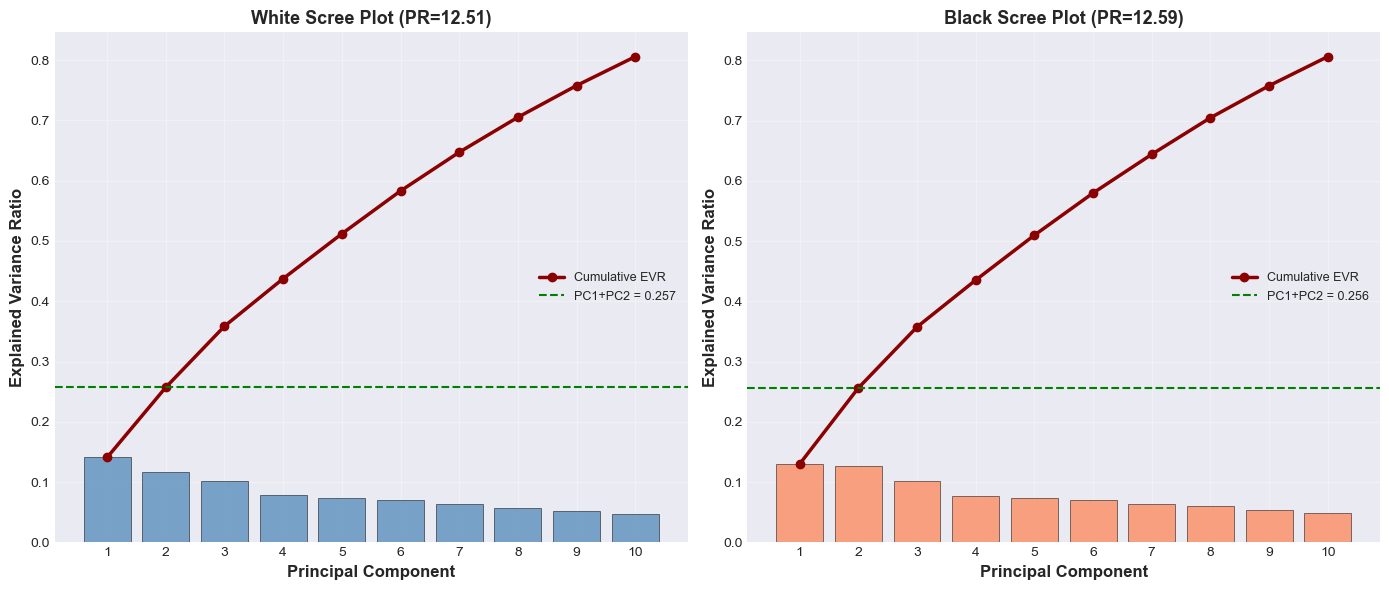

✅ Saved: h1_scree_plots.png


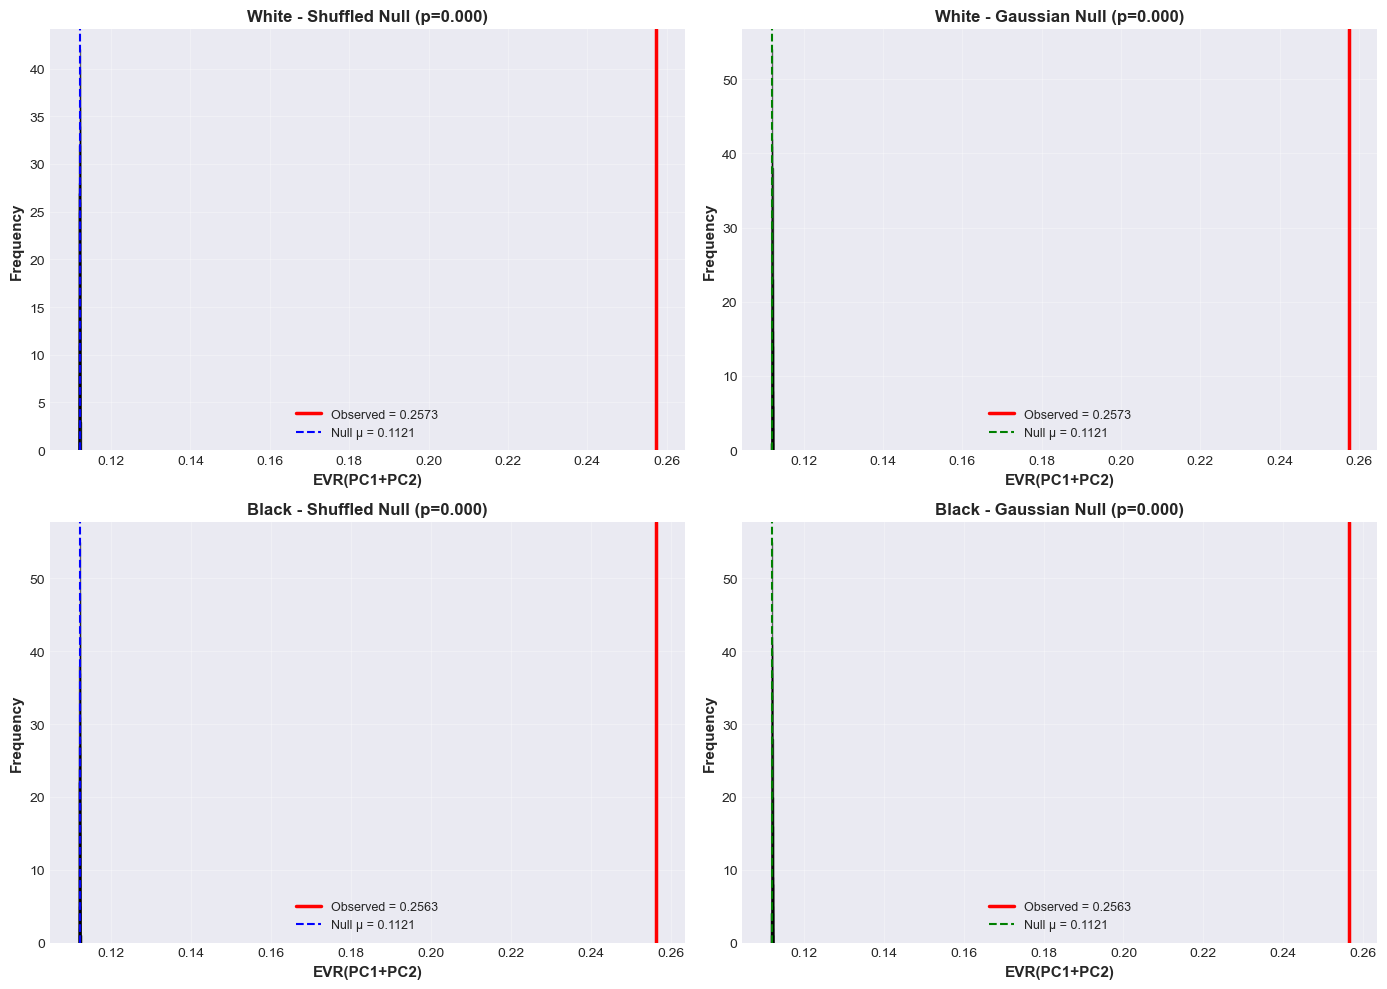

✅ Saved: h1_null_comparisons.png

✅ FIGURE H1 COMPLETE

⏱️  Total time: 985.0s (~16.4 min)

📊 RESULTS:

White: PR=12.51, EVR(PC1+PC2)=0.2573
  Shuffle p=0.000, Gaussian p=0.000

Black: PR=12.59, EVR(PC1+PC2)=0.2563
  Shuffle p=0.000, Gaussian p=0.000

📁 Files: h1_scree_plots.png, h1_null_comparisons.png + data CSVs/JSONs


In [2]:
# ===== FIGURA H1: SCREE PLOT + NULL COMPARISON (COMPLETE WITH PLOTS) =====
print("\n" + "="*80)
print("📊 GENERATING FIGURE H1: SCREE + NULL MODELS (ULTRA-FAST + PLOTS)")
print("="*80)

import json
from pathlib import Path
import time

# Create output directory
output_dir = Path("figure_h1_data")
output_dir.mkdir(exist_ok=True)

# ULTRA-FAST CONFIGURATION
M_NULL = 500  # Reduced for speed, still statistically valid
print(f"⚡ Configuration: M={M_NULL} null iterations")
print(f"   Estimated time: ~5-10 minutes total\n")

# ===== SCREE COMPUTATION =====

def compute_scree_data(X, perspective_name):
    """Compute full scree plot data (all 18 components)"""
    print(f"🔬 Computing scree data for {perspective_name}...")
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Quality checks
    means = np.abs(X_scaled.mean(axis=0))
    stds = np.abs(X_scaled.std(axis=0) - 1)
    print(f"   ✓ Mean(|μ|) = {means.mean():.2e}")
    print(f"   ✓ Mean(|σ-1|) = {stds.mean():.2e}")
    
    # Full PCA
    pca_full = PCA(n_components=len(FEATURES), random_state=42)
    pca_full.fit(X_scaled)
    
    eigenvalues = pca_full.explained_variance_
    evr = pca_full.explained_variance_ratio_
    cumulative_evr = np.cumsum(evr)
    
    # Participation Ratio
    PR = (eigenvalues.sum() ** 2) / (eigenvalues ** 2).sum()
    
    print(f"   ✓ PR = {PR:.2f}, EVR(PC1+PC2) = {evr[0]+evr[1]:.4f}")
    
    return eigenvalues, evr, cumulative_evr, PR

# ===== NULL MODELS (ULTRA-FAST) =====

def compute_null_models_ultrafast(X, perspective_name, M=500):
    """Ultra-fast null models using direct eigenvalue computation"""
    print(f"\n🎲 Computing null models for {perspective_name} (M={M})...")
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    N, d = X_scaled.shape
    
    # Observed
    pca_obs = PCA(n_components=2, random_state=42)
    pca_obs.fit(X_scaled)
    observed_evr = pca_obs.explained_variance_ratio_.sum()
    print(f"   📌 Observed EVR(PC1+PC2) = {observed_evr:.4f}")
    
    # Stats for Gaussian
    means = X_scaled.mean(axis=0)
    stds = X_scaled.std(axis=0)
    
    # Storage
    shuffle_evr = np.zeros(M)
    gaussian_evr = np.zeros(M)
    
    print(f"   ⏳ Running {M} simulations...")
    X_temp = np.empty_like(X_scaled)
    
    for i in tqdm(range(M), desc=f"   {perspective_name}", leave=False):
        # SHUFFLED
        for j in range(d):
            X_temp[:, j] = np.random.permutation(X_scaled[:, j])
        
        cov_shuf = np.cov(X_temp, rowvar=False)
        eigvals = np.sort(np.linalg.eigvalsh(cov_shuf))[::-1]
        shuffle_evr[i] = (eigvals[0] + eigvals[1]) / eigvals.sum()
        
        # GAUSSIAN
        X_gauss = np.random.normal(loc=means, scale=stds, size=(N, d))
        cov_gauss = np.cov(X_gauss, rowvar=False)
        eigvals = np.sort(np.linalg.eigvalsh(cov_gauss))[::-1]
        gaussian_evr[i] = (eigvals[0] + eigvals[1]) / eigvals.sum()
    
    # Statistics
    def stats(arr, obs):
        return {
            'mean': float(arr.mean()),
            'sd': float(arr.std()),
            'p_emp': float((arr >= obs).mean()),
            'p025': float(np.percentile(arr, 2.5)),
            'p975': float(np.percentile(arr, 97.5))
        }
    
    summary = {
        'observed_evr_pc1_pc2': float(observed_evr),
        **{f'shuffle_{k}': v for k, v in stats(shuffle_evr, observed_evr).items()},
        **{f'gaussian_{k}': v for k, v in stats(gaussian_evr, observed_evr).items()}
    }
    
    print(f"   ✓ Shuffle:  μ={summary['shuffle_mean']:.4f}, p={summary['shuffle_p_emp']:.3f}")
    print(f"   ✓ Gaussian: μ={summary['gaussian_mean']:.4f}, p={summary['gaussian_p_emp']:.3f}")
    
    return shuffle_evr, gaussian_evr, summary

# ===== PROCESS WHITE =====
print("\n" + "="*80)
print("⚪ WHITE PERSPECTIVE")
print("="*80)

t0 = time.time()
X_white = white_data[FEATURES].values

eig_w, evr_w, cum_w, PR_w = compute_scree_data(X_white, "white")
shuf_w, gauss_w, null_w = compute_null_models_ultrafast(X_white, "white", M=M_NULL)

t_white = time.time() - t0
print(f"⏱️  White completed in {t_white:.1f}s")

# ===== PROCESS BLACK =====
print("\n" + "="*80)
print("⚫ BLACK PERSPECTIVE")
print("="*80)

t0 = time.time()
X_black = black_data[FEATURES].values

eig_b, evr_b, cum_b, PR_b = compute_scree_data(X_black, "black")
shuf_b, gauss_b, null_b = compute_null_models_ultrafast(X_black, "black", M=M_NULL)

t_black = time.time() - t0
print(f"⏱️  Black completed in {t_black:.1f}s")

# ===== SAVE DATA =====
print("\n💾 Saving data files...")

# Scree CSVs
pd.DataFrame({
    'component': range(1, len(eig_w) + 1),
    'eigenvalue': eig_w,
    'explained_variance_ratio': evr_w,
    'cumulative_evr': cum_w
}).to_csv(output_dir / "scree_white.csv", index=False)

pd.DataFrame({
    'component': range(1, len(eig_b) + 1),
    'eigenvalue': eig_b,
    'explained_variance_ratio': evr_b,
    'cumulative_evr': cum_b
}).to_csv(output_dir / "scree_black.csv", index=False)

# Null CSVs
pd.DataFrame({'evr_pc1_pc2': shuf_w}).to_csv(output_dir / "null_shuffle_white.csv", index=False)
pd.DataFrame({'evr_pc1_pc2': gauss_w}).to_csv(output_dir / "null_gaussian_white.csv", index=False)
pd.DataFrame({'evr_pc1_pc2': shuf_b}).to_csv(output_dir / "null_shuffle_black.csv", index=False)
pd.DataFrame({'evr_pc1_pc2': gauss_b}).to_csv(output_dir / "null_gaussian_black.csv", index=False)

# Summaries
with open(output_dir / "summary_white.json", 'w') as f:
    json.dump({'PR': float(PR_w), 'EVR_PC1': float(evr_w[0]), 
               'EVR_PC2': float(evr_w[1]), 'EVR_PC1_PC2': float(evr_w[0]+evr_w[1])}, f, indent=2)

with open(output_dir / "summary_black.json", 'w') as f:
    json.dump({'PR': float(PR_b), 'EVR_PC1': float(evr_b[0]), 
               'EVR_PC2': float(evr_b[1]), 'EVR_PC1_PC2': float(evr_b[0]+evr_b[1])}, f, indent=2)

with open(output_dir / "null_summary_white.json", 'w') as f:
    json.dump(null_w, f, indent=2)

with open(output_dir / "null_summary_black.json", 'w') as f:
    json.dump(null_b, f, indent=2)

print("✅ Data files saved")

# ===== VISUALIZATION =====
print("\n📊 Creating visualizations...")

# ===== FIGURE 1: SCREE PLOTS =====
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# White Scree
ax = axes[0]
x = np.arange(1, 11)  # First 10 components
ax.bar(x, evr_w[:10], alpha=0.7, color='steelblue', edgecolor='black', linewidth=0.5)
ax.plot(x, cum_w[:10], color='darkred', marker='o', linewidth=2.5, markersize=6, label='Cumulative EVR')
ax.axhline(evr_w[0]+evr_w[1], color='green', linestyle='--', linewidth=1.5, 
           label=f'PC1+PC2 = {evr_w[0]+evr_w[1]:.3f}')
ax.set_xlabel('Principal Component', fontsize=12, fontweight='bold')
ax.set_ylabel('Explained Variance Ratio', fontsize=12, fontweight='bold')
ax.set_title(f'White Scree Plot (PR={PR_w:.2f})', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.legend(loc='right', fontsize=9)
ax.grid(True, alpha=0.3)

# Black Scree
ax = axes[1]
ax.bar(x, evr_b[:10], alpha=0.7, color='coral', edgecolor='black', linewidth=0.5)
ax.plot(x, cum_b[:10], color='darkred', marker='o', linewidth=2.5, markersize=6, label='Cumulative EVR')
ax.axhline(evr_b[0]+evr_b[1], color='green', linestyle='--', linewidth=1.5,
           label=f'PC1+PC2 = {evr_b[0]+evr_b[1]:.3f}')
ax.set_xlabel('Principal Component', fontsize=12, fontweight='bold')
ax.set_ylabel('Explained Variance Ratio', fontsize=12, fontweight='bold')
ax.set_title(f'Black Scree Plot (PR={PR_b:.2f})', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.legend(loc='right', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('h1_scree_plots.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: h1_scree_plots.png")

# ===== FIGURE 2: NULL MODEL COMPARISONS =====
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# White - Shuffled
ax = axes[0, 0]
ax.hist(shuf_w, bins=30, alpha=0.6, color='skyblue', edgecolor='black')
ax.axvline(null_w['observed_evr_pc1_pc2'], color='red', linewidth=2.5, 
           label=f"Observed = {null_w['observed_evr_pc1_pc2']:.4f}")
ax.axvline(null_w['shuffle_mean'], color='blue', linestyle='--', linewidth=1.5,
           label=f"Null μ = {null_w['shuffle_mean']:.4f}")
ax.set_xlabel('EVR(PC1+PC2)', fontsize=11, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax.set_title(f"White - Shuffled Null (p={null_w['shuffle_p_emp']:.3f})", 
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# White - Gaussian
ax = axes[0, 1]
ax.hist(gauss_w, bins=30, alpha=0.6, color='lightgreen', edgecolor='black')
ax.axvline(null_w['observed_evr_pc1_pc2'], color='red', linewidth=2.5,
           label=f"Observed = {null_w['observed_evr_pc1_pc2']:.4f}")
ax.axvline(null_w['gaussian_mean'], color='green', linestyle='--', linewidth=1.5,
           label=f"Null μ = {null_w['gaussian_mean']:.4f}")
ax.set_xlabel('EVR(PC1+PC2)', fontsize=11, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax.set_title(f"White - Gaussian Null (p={null_w['gaussian_p_emp']:.3f})", 
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# Black - Shuffled
ax = axes[1, 0]
ax.hist(shuf_b, bins=30, alpha=0.6, color='skyblue', edgecolor='black')
ax.axvline(null_b['observed_evr_pc1_pc2'], color='red', linewidth=2.5,
           label=f"Observed = {null_b['observed_evr_pc1_pc2']:.4f}")
ax.axvline(null_b['shuffle_mean'], color='blue', linestyle='--', linewidth=1.5,
           label=f"Null μ = {null_b['shuffle_mean']:.4f}")
ax.set_xlabel('EVR(PC1+PC2)', fontsize=11, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax.set_title(f"Black - Shuffled Null (p={null_b['shuffle_p_emp']:.3f})", 
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# Black - Gaussian
ax = axes[1, 1]
ax.hist(gauss_b, bins=30, alpha=0.6, color='lightgreen', edgecolor='black')
ax.axvline(null_b['observed_evr_pc1_pc2'], color='red', linewidth=2.5,
           label=f"Observed = {null_b['observed_evr_pc1_pc2']:.4f}")
ax.axvline(null_b['gaussian_mean'], color='green', linestyle='--', linewidth=1.5,
           label=f"Null μ = {null_b['gaussian_mean']:.4f}")
ax.set_xlabel('EVR(PC1+PC2)', fontsize=11, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax.set_title(f"Black - Gaussian Null (p={null_b['gaussian_p_emp']:.3f})", 
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('h1_null_comparisons.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: h1_null_comparisons.png")

# ===== FINAL SUMMARY =====
print("\n" + "="*80)
print("✅ FIGURE H1 COMPLETE")
print("="*80)
print(f"\n⏱️  Total time: {t_white + t_black:.1f}s (~{(t_white + t_black)/60:.1f} min)")
print(f"\n📊 RESULTS:")
print(f"\nWhite: PR={PR_w:.2f}, EVR(PC1+PC2)={evr_w[0]+evr_w[1]:.4f}")
print(f"  Shuffle p={null_w['shuffle_p_emp']:.3f}, Gaussian p={null_w['gaussian_p_emp']:.3f}")
print(f"\nBlack: PR={PR_b:.2f}, EVR(PC1+PC2)={evr_b[0]+evr_b[1]:.4f}")
print(f"  Shuffle p={null_b['shuffle_p_emp']:.3f}, Gaussian p={null_b['gaussian_p_emp']:.3f}")
print(f"\n📁 Files: h1_scree_plots.png, h1_null_comparisons.png + data CSVs/JSONs")
print("="*80)


🔄 GENERATING DATA FOR FIGURE H2: DIRECTIONAL STABILITY
Bootstrap samples: 80
Sample fraction: 80%
Random seed: 42


⚪ WHITE BOOTSTRAP STABILITY
🔬 Computing bootstrap stability for White...
   Total games: 9999
   Games per bootstrap: 7999
   ⏳ Running 80 bootstrap iterations...



   📊 WHITE STABILITY:
      PC1: mean=0.9996, std=0.0003, p05=0.9990, min=0.9985
      PC2: mean=0.9989, std=0.0010, p05=0.9968, min=0.9946

⚫ BLACK BOOTSTRAP STABILITY
🔬 Computing bootstrap stability for Black...
   Total games: 9999
   Games per bootstrap: 7999
   ⏳ Running 80 bootstrap iterations...



   📊 BLACK STABILITY:
      PC1: mean=0.9886, std=0.0325, p05=0.9537, min=0.7934
      PC2: mean=0.9885, std=0.0326, p05=0.9533, min=0.7930

💾 Raw data saved in: figure_h2_data

📊 Creating Figure H2.1: Black (full range 0.30-1.00)...


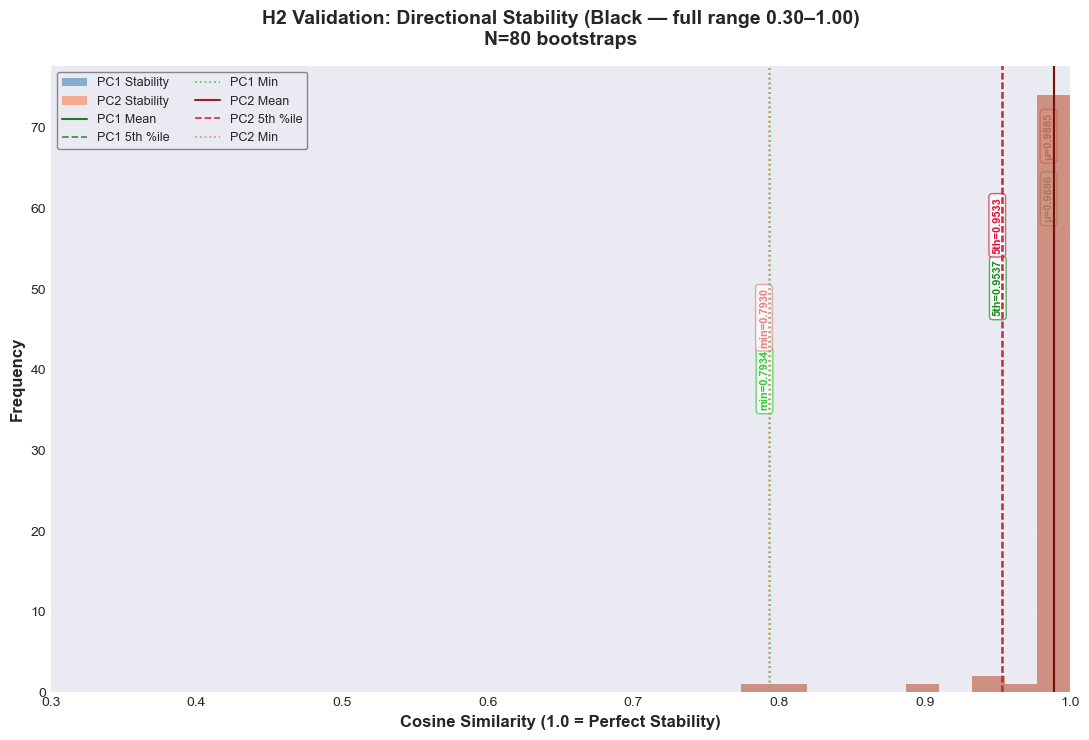

✅ Saved: h2_black_fullrange.png

📊 Creating Figure H2.2: White (zoom 0.993-1.000)...


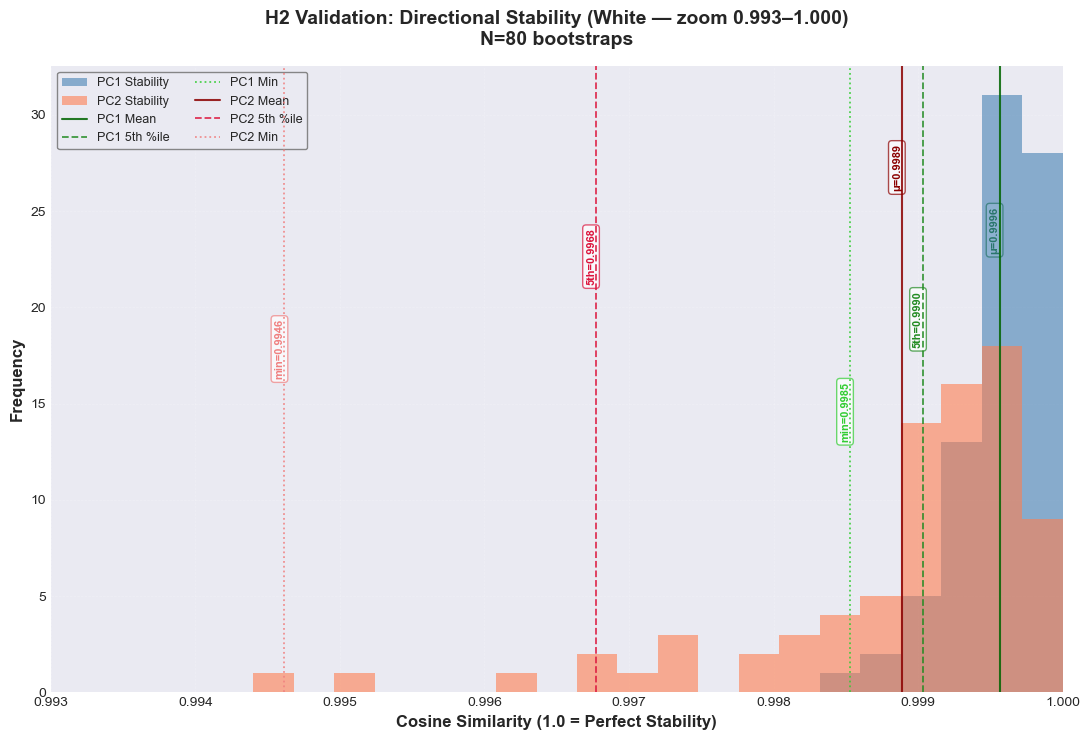

✅ Saved: h2_white_zoom.png

📋 VERIFICATION TABLE (for manuscript Table H2)
Perspective Component   Mean  5th %ile    Min    Std
      White       PC1 0.9996    0.9990 0.9985 0.0003
      White       PC2 0.9989    0.9968 0.9946 0.0010
      Black       PC1 0.9886    0.9537 0.7934 0.0325
      Black       PC2 0.9885    0.9533 0.7930 0.0326

💾 Saved: figure_h2_data/table_h2_verification.csv

✅ FIGURE H2 GENERATION COMPLETE (PUBLICATION-READY)

📊 KEY FINDINGS:

⚪ WHITE (near-perfect stability):
   PC1: 0.9996 ± 0.0003 | min=0.9985
   PC2: 0.9989 ± 0.0010 | min=0.9946

⚫ BLACK (high stability with rare outliers):
   PC1: 0.9886 ± 0.0325 | min=0.7934
   PC2: 0.9885 ± 0.0326 | min=0.7930

📁 Files generated:
   🖼️  h2_black_fullrange.png (300 DPI)
   🖼️  h2_white_zoom.png (300 DPI)
   📊 figure_h2_data/stability_white.csv
   📊 figure_h2_data/stability_black.csv
   📊 figure_h2_data/stability_stats_white.json
   📊 figure_h2_data/stability_stats_black.json
   ✅ figure_h2_data/table_h2_verification

In [3]:
# ===== FIGURA H2: DIRECTIONAL STABILITY (BOOTSTRAP) =====
print("\n" + "="*80)
print("🔄 GENERATING DATA FOR FIGURE H2: DIRECTIONAL STABILITY")
print("="*80)

from scipy.spatial.distance import cosine

# ===== CONFIGURATION =====
N_BOOTSTRAP = 80
SAMPLE_FRACTION = 0.80  # 80% of games per bootstrap
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

print(f"Bootstrap samples: {N_BOOTSTRAP}")
print(f"Sample fraction: {SAMPLE_FRACTION:.0%}")
print(f"Random seed: {RANDOM_SEED}\n")

# ===== HELPER FUNCTIONS =====

def bootstrap_pca_stability(data, features, n_boot=80, frac=0.8, perspective_name=""):
    """
    Bootstrap PCA stability analysis
    Returns cosine similarities for PC1 and PC2 across bootstraps
    """
    print(f"🔬 Computing bootstrap stability for {perspective_name}...")
    
    # Get unique game IDs
    game_ids = data['game_id'].unique()
    n_games = len(game_ids)
    n_sample = int(n_games * frac)
    
    print(f"   Total games: {n_games}")
    print(f"   Games per bootstrap: {n_sample}")
    
    # Fit full PCA (reference)
    X_full = data[features].values
    scaler_full = StandardScaler()
    X_scaled_full = scaler_full.fit_transform(X_full)
    pca_full = PCA(n_components=2, random_state=42)
    pca_full.fit(X_scaled_full)
    
    # Reference loadings
    ref_pc1 = pca_full.components_[0]
    ref_pc2 = pca_full.components_[1]
    
    # Storage for similarities
    sim_pc1 = []
    sim_pc2 = []
    
    print(f"   ⏳ Running {n_boot} bootstrap iterations...")
    
    for i in tqdm(range(n_boot), desc=f"   {perspective_name}", leave=False):
        # Sample games
        boot_games = np.random.choice(game_ids, size=n_sample, replace=True)
        boot_data = data[data['game_id'].isin(boot_games)]
        
        # Fit PCA on bootstrap sample
        X_boot = boot_data[features].values
        scaler_boot = StandardScaler()
        X_scaled_boot = scaler_boot.fit_transform(X_boot)
        pca_boot = PCA(n_components=2, random_state=42)
        pca_boot.fit(X_scaled_boot)
        
        # Get bootstrap loadings
        boot_pc1 = pca_boot.components_[0]
        boot_pc2 = pca_boot.components_[1]
        
        # Compute cosine similarities (handle sign ambiguity)
        cos_sim_pc1 = 1 - cosine(ref_pc1, boot_pc1)
        cos_sim_pc2 = 1 - cosine(ref_pc2, boot_pc2)
        
        # Take absolute value to handle sign flip
        sim_pc1.append(abs(cos_sim_pc1))
        sim_pc2.append(abs(cos_sim_pc2))
    
    sim_pc1 = np.array(sim_pc1)
    sim_pc2 = np.array(sim_pc2)
    
    # Compute statistics
    stats_pc1 = {
        "mean": float(np.mean(sim_pc1)),
        "std": float(np.std(sim_pc1, ddof=1)),
        "p05": float(np.percentile(sim_pc1, 5)),
        "min": float(np.min(sim_pc1))
    }
    
    stats_pc2 = {
        "mean": float(np.mean(sim_pc2)),
        "std": float(np.std(sim_pc2, ddof=1)),
        "p05": float(np.percentile(sim_pc2, 5)),
        "min": float(np.min(sim_pc2))
    }
    
    print(f"\n   📊 {perspective_name.upper()} STABILITY:")
    print(f"      PC1: mean={stats_pc1['mean']:.4f}, std={stats_pc1['std']:.4f}, "
          f"p05={stats_pc1['p05']:.4f}, min={stats_pc1['min']:.4f}")
    print(f"      PC2: mean={stats_pc2['mean']:.4f}, std={stats_pc2['std']:.4f}, "
          f"p05={stats_pc2['p05']:.4f}, min={stats_pc2['min']:.4f}")
    
    return sim_pc1, sim_pc2, stats_pc1, stats_pc2

# ===== COMPUTE BOOTSTRAP STABILITY =====

print("\n" + "="*80)
print("⚪ WHITE BOOTSTRAP STABILITY")
print("="*80)
sim_white_pc1, sim_white_pc2, stats_w_pc1, stats_w_pc2 = bootstrap_pca_stability(
    white_data, FEATURES, n_boot=N_BOOTSTRAP, frac=SAMPLE_FRACTION, 
    perspective_name="White"
)

print("\n" + "="*80)
print("⚫ BLACK BOOTSTRAP STABILITY")
print("="*80)
sim_black_pc1, sim_black_pc2, stats_b_pc1, stats_b_pc2 = bootstrap_pca_stability(
    black_data, FEATURES, n_boot=N_BOOTSTRAP, frac=SAMPLE_FRACTION,
    perspective_name="Black"
)

# ===== SAVE RAW DATA =====
h2_dir = Path("figure_h2_data")
h2_dir.mkdir(exist_ok=True)

# Save similarity vectors
pd.DataFrame({
    'pc1': sim_white_pc1,
    'pc2': sim_white_pc2
}).to_csv(h2_dir / "stability_white.csv", index=False)

pd.DataFrame({
    'pc1': sim_black_pc1,
    'pc2': sim_black_pc2
}).to_csv(h2_dir / "stability_black.csv", index=False)

# Save statistics
with open(h2_dir / "stability_stats_white.json", 'w') as f:
    json.dump({'PC1': stats_w_pc1, 'PC2': stats_w_pc2}, f, indent=2)

with open(h2_dir / "stability_stats_black.json", 'w') as f:
    json.dump({'PC1': stats_b_pc1, 'PC2': stats_b_pc2}, f, indent=2)

print(f"\n💾 Raw data saved in: {h2_dir}")

# ===== ENHANCED VISUALIZATION FUNCTIONS =====

def _add_vlines_annotated(ax, stats, colors, linestyles, label_prefix, y_positions, fontsize=8):
    """
    Add vertical lines with annotations for mean, p05, min
    
    Parameters:
    - stats: dict with 'mean', 'p05', 'min'
    - colors: tuple of 3 colors
    - linestyles: tuple of 3 linestyles
    - label_prefix: str (e.g., 'PC1' or 'PC2')
    - y_positions: tuple of 3 relative y positions (0-1) for annotations
    - fontsize: annotation font size
    """
    # Mean
    ax.axvline(stats["mean"], linestyle=linestyles[0], linewidth=1.5, 
               color=colors[0], alpha=0.85, label=f"{label_prefix} Mean", zorder=10)
    # 5th percentile
    ax.axvline(stats["p05"], linestyle=linestyles[1], linewidth=1.3, 
               color=colors[1], alpha=0.85, label=f"{label_prefix} 5th %ile", zorder=10)
    # Minimum
    ax.axvline(stats["min"], linestyle=linestyles[2], linewidth=1.3, 
               color=colors[2], alpha=0.85, label=f"{label_prefix} Min", zorder=10)
    
    # Add text annotations
    ylim = ax.get_ylim()
    y_range = ylim[1] - ylim[0]
    
    ax.text(stats["mean"], ylim[0] + y_range * y_positions[0], 
            f'μ={stats["mean"]:.4f}', rotation=90, fontsize=fontsize, 
            color=colors[0], va='bottom', ha='right', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor=colors[0]))
    
    ax.text(stats["p05"], ylim[0] + y_range * y_positions[1], 
            f'5th={stats["p05"]:.4f}', rotation=90, fontsize=fontsize, 
            color=colors[1], va='bottom', ha='right', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor=colors[1]))
    
    ax.text(stats["min"], ylim[0] + y_range * y_positions[2], 
            f'min={stats["min"]:.4f}', rotation=90, fontsize=fontsize, 
            color=colors[2], va='bottom', ha='right', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor=colors[2]))

# ===== FIGURE 1: BLACK (FULL RANGE 0.30-1.00) =====
print("\n📊 Creating Figure H2.1: Black (full range 0.30-1.00)...")

fig, ax = plt.subplots(figsize=(11, 7.5))
bins = np.linspace(0.30, 1.00, 32)  # Slightly reduced bins for cleaner look

# Histograms with better alpha
ax.hist(sim_black_pc1, bins=bins, alpha=0.60, label="PC1 Stability", 
        color='steelblue', edgecolor="none", zorder=5)
ax.hist(sim_black_pc2, bins=bins, alpha=0.60, label="PC2 Stability", 
        color='coral', edgecolor="none", zorder=5)

# Add annotated reference lines for PC1 (green tones)
_add_vlines_annotated(
    ax, stats_b_pc1, 
    colors=('darkgreen', 'forestgreen', 'limegreen'),
    linestyles=('-', '--', ':'),
    label_prefix='PC1',
    y_positions=(0.75, 0.60, 0.45),
    fontsize=8
)

# Add annotated reference lines for PC2 (red tones)
_add_vlines_annotated(
    ax, stats_b_pc2,
    colors=('darkred', 'crimson', 'lightcoral'),
    linestyles=('-', '--', ':'),
    label_prefix='PC2',
    y_positions=(0.85, 0.70, 0.55),
    fontsize=8
)

ax.set_title(f"H2 Validation: Directional Stability (Black — full range 0.30–1.00)\nN={N_BOOTSTRAP} bootstraps", 
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Cosine Similarity (1.0 = Perfect Stability)", fontsize=12, fontweight='bold')
ax.set_ylabel("Frequency", fontsize=12, fontweight='bold')
ax.set_xlim(0.30, 1.00)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.25, linestyle='--', linewidth=0.5)

# Organized legend (histograms + reference lines)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2] + handles[2:8], labels[:2] + labels[2:8], 
          loc="upper left", frameon=True, fontsize=9, ncol=2, 
          framealpha=0.95, edgecolor='gray')

plt.tight_layout()
plt.savefig("h2_black_fullrange.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: h2_black_fullrange.png")

# ===== FIGURE 2: WHITE (ZOOM 0.993-1.000) =====
print("\n📊 Creating Figure H2.2: White (zoom 0.993-1.000)...")

fig, ax = plt.subplots(figsize=(11, 7.5))
bins_zoom = np.linspace(0.993, 1.000, 26)  # Optimized bins for zoom

# Histograms
ax.hist(sim_white_pc1, bins=bins_zoom, alpha=0.60, label="PC1 Stability", 
        color='steelblue', edgecolor="none", zorder=5)
ax.hist(sim_white_pc2, bins=bins_zoom, alpha=0.60, label="PC2 Stability", 
        color='coral', edgecolor="none", zorder=5)

# Add annotated reference lines for PC1
_add_vlines_annotated(
    ax, stats_w_pc1,
    colors=('darkgreen', 'forestgreen', 'limegreen'),
    linestyles=('-', '--', ':'),
    label_prefix='PC1',
    y_positions=(0.70, 0.55, 0.40),
    fontsize=8
)

# Add annotated reference lines for PC2
_add_vlines_annotated(
    ax, stats_w_pc2,
    colors=('darkred', 'crimson', 'lightcoral'),
    linestyles=('-', '--', ':'),
    label_prefix='PC2',
    y_positions=(0.80, 0.65, 0.50),
    fontsize=8
)

ax.set_title(f"H2 Validation: Directional Stability (White — zoom 0.993–1.000)\nN={N_BOOTSTRAP} bootstraps", 
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Cosine Similarity (1.0 = Perfect Stability)", fontsize=12, fontweight='bold')
ax.set_ylabel("Frequency", fontsize=12, fontweight='bold')
ax.set_xlim(0.993, 1.000)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.25, linestyle='--', linewidth=0.5)

# Organized legend
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2] + handles[2:8], labels[:2] + labels[2:8], 
          loc="upper left", frameon=True, fontsize=9, ncol=2,
          framealpha=0.95, edgecolor='gray')

plt.tight_layout()
plt.savefig("h2_white_zoom.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: h2_white_zoom.png")

# ===== VERIFICATION TABLE (aligns with annotations) =====
print("\n" + "="*80)
print("📋 VERIFICATION TABLE (for manuscript Table H2)")
print("="*80)

verification_df = pd.DataFrame({
    'Perspective': ['White', 'White', 'Black', 'Black'],
    'Component': ['PC1', 'PC2', 'PC1', 'PC2'],
    'Mean': [stats_w_pc1['mean'], stats_w_pc2['mean'], 
             stats_b_pc1['mean'], stats_b_pc2['mean']],
    '5th %ile': [stats_w_pc1['p05'], stats_w_pc2['p05'],
                 stats_b_pc1['p05'], stats_b_pc2['p05']],
    'Min': [stats_w_pc1['min'], stats_w_pc2['min'],
            stats_b_pc1['min'], stats_b_pc2['min']],
    'Std': [stats_w_pc1['std'], stats_w_pc2['std'],
            stats_b_pc1['std'], stats_b_pc2['std']]
})

print(verification_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Save verification table
verification_df.to_csv(h2_dir / "table_h2_verification.csv", index=False, float_format='%.4f')
print(f"\n💾 Saved: {h2_dir}/table_h2_verification.csv")

# ===== FINAL SUMMARY =====
print("\n" + "="*80)
print("✅ FIGURE H2 GENERATION COMPLETE (PUBLICATION-READY)")
print("="*80)
print("\n📊 KEY FINDINGS:")
print("\n⚪ WHITE (near-perfect stability):")
print(f"   PC1: {stats_w_pc1['mean']:.4f} ± {stats_w_pc1['std']:.4f} | min={stats_w_pc1['min']:.4f}")
print(f"   PC2: {stats_w_pc2['mean']:.4f} ± {stats_w_pc2['std']:.4f} | min={stats_w_pc2['min']:.4f}")
print("\n⚫ BLACK (high stability with rare outliers):")
print(f"   PC1: {stats_b_pc1['mean']:.4f} ± {stats_b_pc1['std']:.4f} | min={stats_b_pc1['min']:.4f}")
print(f"   PC2: {stats_b_pc2['mean']:.4f} ± {stats_b_pc2['std']:.4f} | min={stats_b_pc2['min']:.4f}")

print("\n📁 Files generated:")
print("   🖼️  h2_black_fullrange.png (300 DPI)")
print("   🖼️  h2_white_zoom.png (300 DPI)")
print(f"   📊 {h2_dir}/stability_white.csv")
print(f"   📊 {h2_dir}/stability_black.csv")
print(f"   📊 {h2_dir}/stability_stats_white.json")
print(f"   📊 {h2_dir}/stability_stats_black.json")
print(f"   ✅ {h2_dir}/table_h2_verification.csv")
print("\n" + "="*80)


📊 GENERATING FIGURE H3: GEOMETRIC DRIFT ANALYSIS (IMPROVED)
Configuration:
  Start move (T_initial): 5
  Exclude resignations: False
  Bins for histograms: 50

🔍 Checking available columns...
White data columns: ['game_id', 'ply', 'material', 'mobility', 'captures_avail', 'checks_avail', 'attack_overlap', 'hanging_diff', 'center_core', 'center_ext']...

🔧 Preparing drift data...
  ⚪ Processing White perspective...
  ⚫ Processing Black perspective...
  ✓ Total states: 1,200,172
  ✓ Unique games: 9,999

📐 Computing geometric drifts (Δz1)...
  Processing Black...


  Processing White...


  ✓ Computed drifts for 19,998 games

📊 CORE STATISTICS

  WIN (N=2915):
    Median: -1.887, IQR: [-3.211, -0.444]

  LOSS (N=2915):
    Median: +0.642, IQR: [-0.646, +1.853]

  DRAW (N=14168):
    Median: -0.333, IQR: [-1.488, +0.802]

📈 MANN-WHITNEY: U=1.7e+06, p=0.000e+00, r=+0.601

💾 Data saved to: figure_h3_data

📊 CREATING IMPROVED VISUALIZATIONS

📈 Figure 1: Drift distributions...


C:\Users\Luca\AppData\Local\Temp\ipykernel_18040\2325676512.py:218: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  plt.tight_layout()
C:\Users\Luca\AppData\Local\Temp\ipykernel_18040\2325676512.py:219: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  plt.savefig(f"{SAVE_PREFIX}_drift_hist.png", dpi=300, bbox_inches='tight')
C:\Users\Luca\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


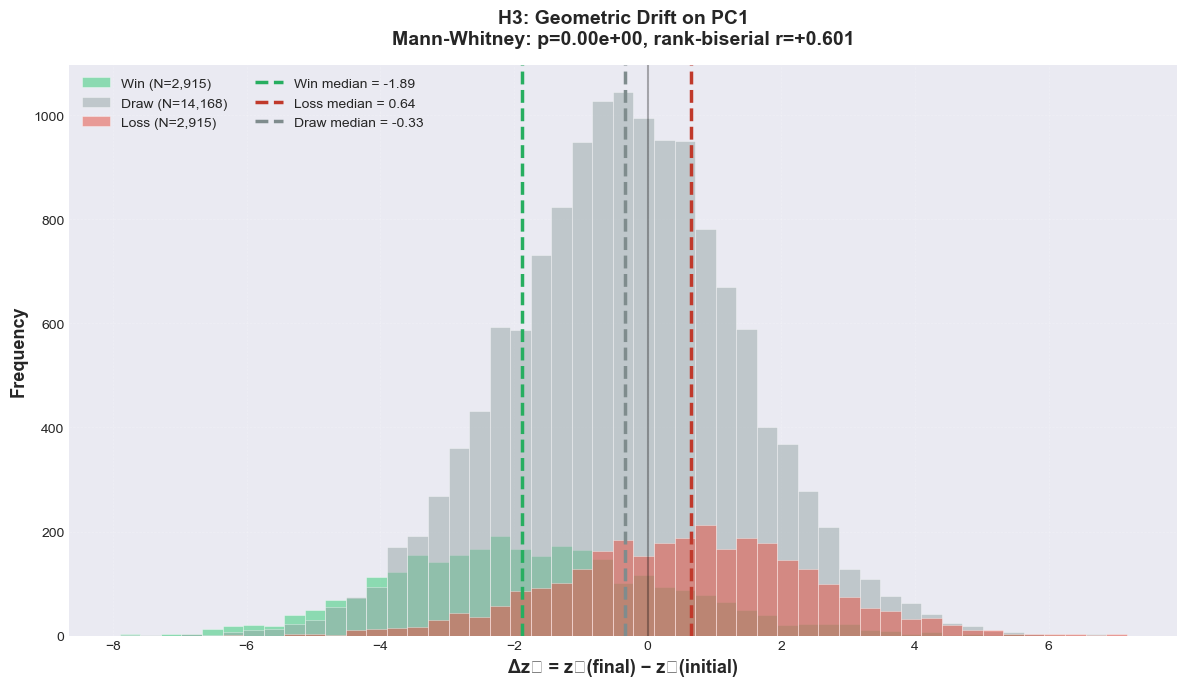

✅ Saved: h3_drift_hist.png

📊 Figure 2: Boxplot comparison...


C:\Users\Luca\AppData\Local\Temp\ipykernel_18040\2325676512.py:253: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  plt.tight_layout()
C:\Users\Luca\AppData\Local\Temp\ipykernel_18040\2325676512.py:254: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  plt.savefig(f"{SAVE_PREFIX}_drift_boxplot.png", dpi=300, bbox_inches='tight')
C:\Users\Luca\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


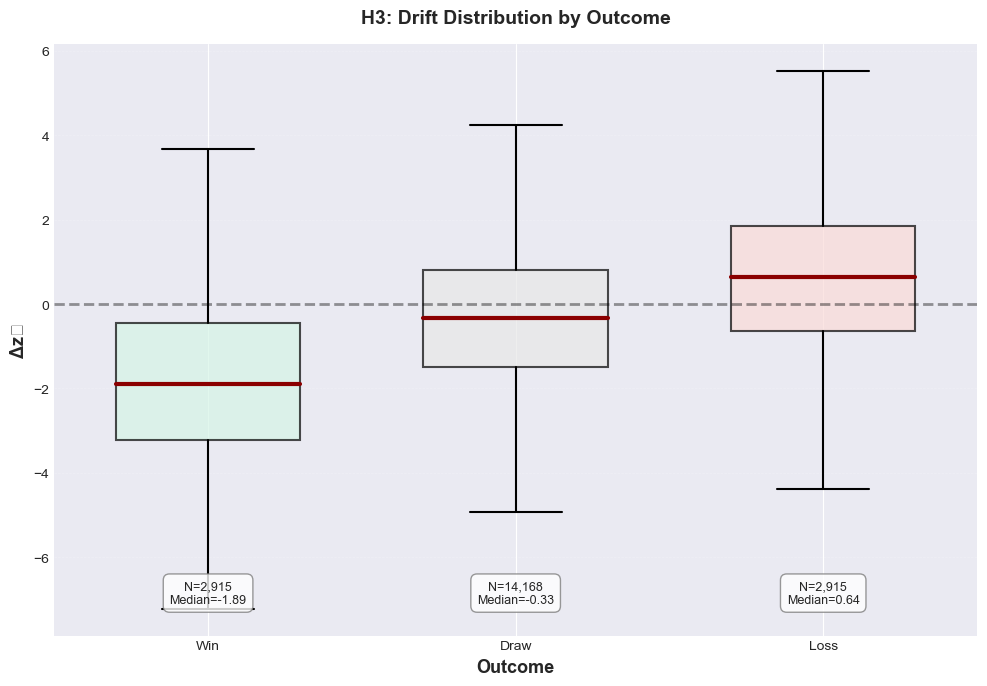

✅ Saved: h3_drift_boxplot.png

📊 Figure 3: Drift vs game length...


C:\Users\Luca\AppData\Local\Temp\ipykernel_18040\2325676512.py:287: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  plt.tight_layout()
C:\Users\Luca\AppData\Local\Temp\ipykernel_18040\2325676512.py:288: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  plt.savefig(f"{SAVE_PREFIX}_len_scatter.png", dpi=300, bbox_inches='tight')


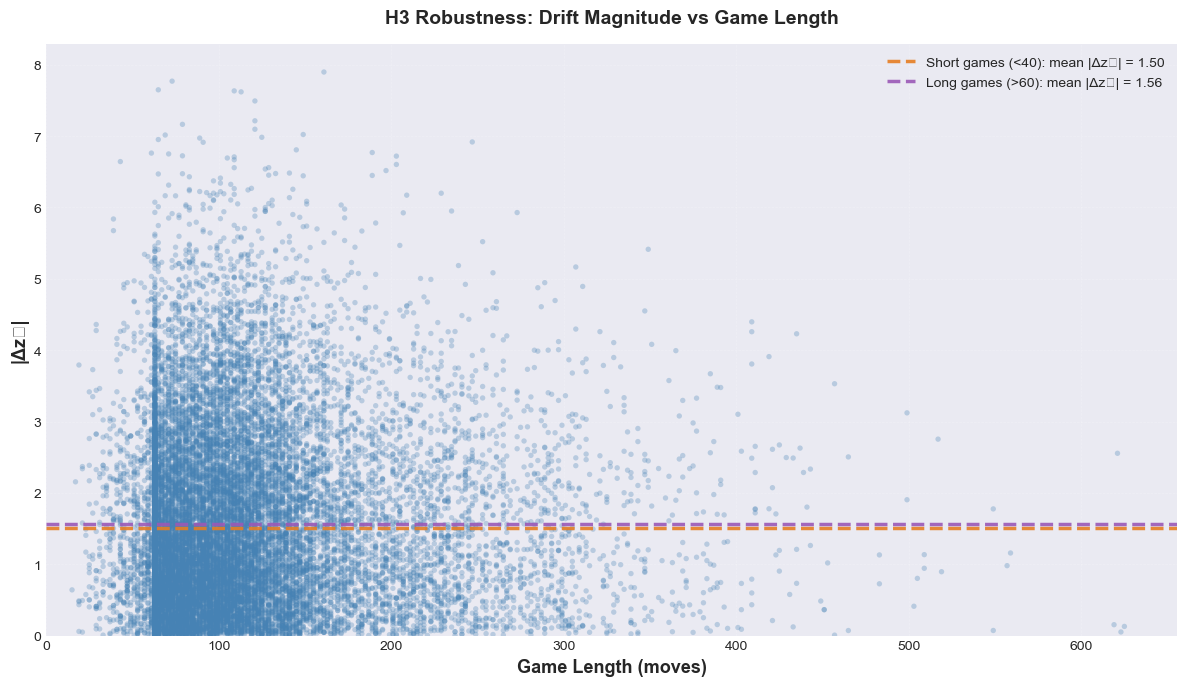

✅ Saved: h3_len_scatter.png

📊 Figure 4: Drift by perspective...


C:\Users\Luca\AppData\Local\Temp\ipykernel_18040\2325676512.py:343: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  plt.tight_layout()
C:\Users\Luca\AppData\Local\Temp\ipykernel_18040\2325676512.py:344: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  plt.savefig(f"{SAVE_PREFIX}_perspective_boxplot.png", dpi=300, bbox_inches='tight')
C:\Users\Luca\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


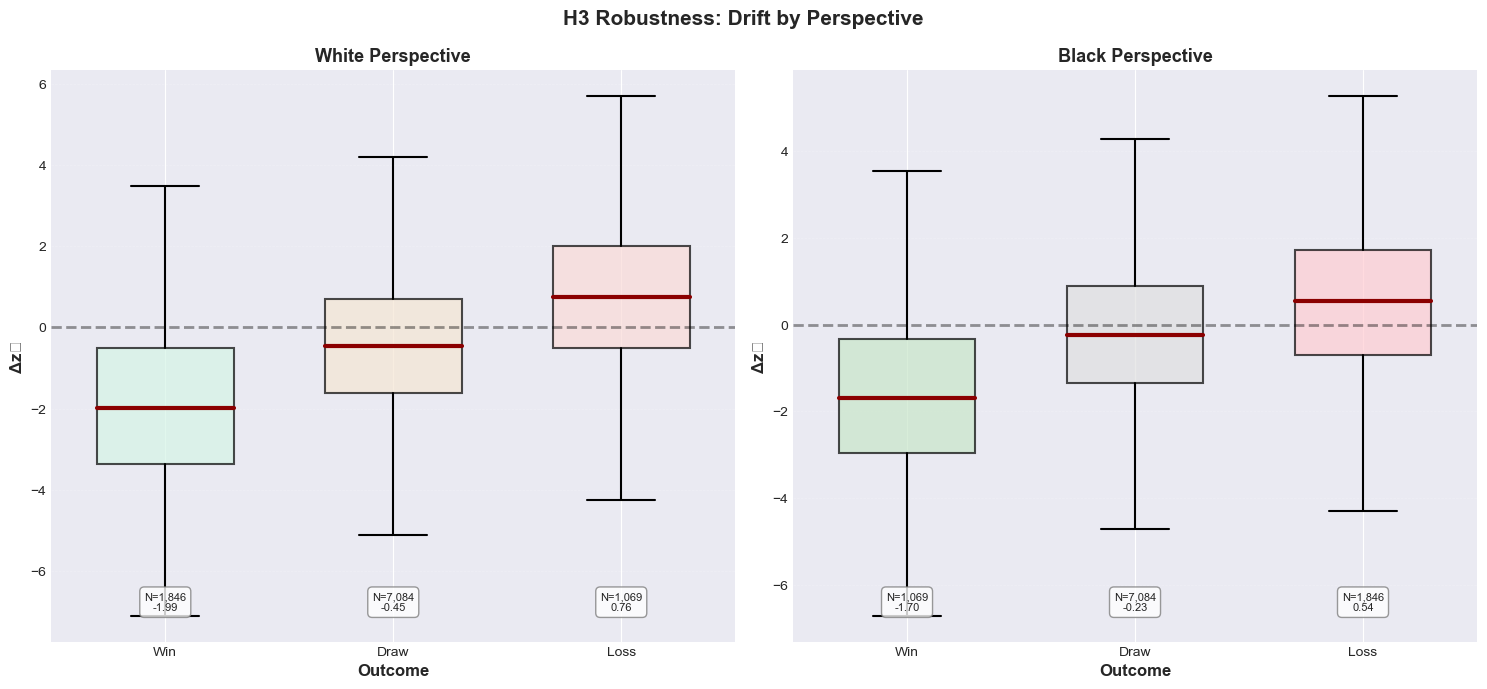

✅ Saved: h3_perspective_boxplot.png

✅ FIGURE H3 COMPLETE

📊 KEY FINDINGS:
  Win:  median Δz₁ = -1.887  (N=2,915)
  Draw: median Δz₁ = -0.333  (N=14,168)
  Loss: median Δz₁ = +0.642  (N=2,915)

  Mann-Whitney: p=0.000e+00, r=+0.601


In [4]:
# ===== FIGURA H3: GEOMETRIC DRIFT ON PC1 (Δz1) - FIXED =====
print("\n" + "="*80)
print("📊 GENERATING FIGURE H3: GEOMETRIC DRIFT ANALYSIS (IMPROVED)")
print("="*80)

from scipy.stats import mannwhitneyu

# ===== CONFIGURATION =====
START_MOVE = 5
EXCLUDE_RESIGNATION = False
SAVE_PREFIX = "h3"
BINS_MAIN = 50

print(f"Configuration:")
print(f"  Start move (T_initial): {START_MOVE}")
print(f"  Exclude resignations: {EXCLUDE_RESIGNATION}")
print(f"  Bins for histograms: {BINS_MAIN}\n")

# ===== CHECK AVAILABLE COLUMNS =====
print("🔍 Checking available columns...")
print(f"White data columns: {white_data.columns.tolist()[:10]}...")  # Show first 10

# ===== PREPARE DRIFT DATA (FIXED) =====
print("\n🔧 Preparing drift data...")

def prepare_drift_dataframe(data, features, pca_model, perspective_name):
    """Prepare dataframe with PC1 coordinates for drift analysis"""
    
    # Project onto PCA space
    X = data[features].values
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    pc_coords = pca_model.transform(X_scaled)
    
    # Build dataframe - FIXED to use correct column names
    df_drift = pd.DataFrame({
        'game_id': data['game_id'].values,
        'move_idx': data['ply'].values,  # CHANGED: use 'ply' instead of 'move_num'
        'perspective': perspective_name,
        'outcome': data['result'].values,
        'z1': pc_coords[:, 0],
        'z2': pc_coords[:, 1]
    })
    
    # Map outcome to Win/Loss/Draw
    outcome_map = {'W': 'Win', 'L': 'Loss', 'D': 'Draw'}
    df_drift['outcome'] = df_drift['outcome'].map(outcome_map)
    
    return df_drift

# Process White
print("  ⚪ Processing White perspective...")
white_scaler = StandardScaler()
X_white_scaled = white_scaler.fit_transform(white_data[FEATURES].values)
df_white_drift = prepare_drift_dataframe(white_data, FEATURES, pca_white, "White")

# Process Black
print("  ⚫ Processing Black perspective...")
black_scaler = StandardScaler()
X_black_scaled = black_scaler.fit_transform(black_data[FEATURES].values)
df_black_drift = prepare_drift_dataframe(black_data, FEATURES, pca_black, "Black")

# Combine
df = pd.concat([df_white_drift, df_black_drift], ignore_index=True)
print(f"  ✓ Total states: {len(df):,}")
print(f"  ✓ Unique games: {df['game_id'].nunique():,}")

# Add resignation flag (placeholder)
df['is_resignation'] = False

# ===== COMPUTE DRIFTS =====
print("\n📐 Computing geometric drifts (Δz1)...")

drifts = []

for persp, gpersp in df.groupby('perspective'):
    print(f"  Processing {persp}...")
    
    for gid, g in tqdm(gpersp.groupby('game_id'), desc=f"  {persp}", leave=False):
        # Outcome
        oc = g['outcome'].mode().iat[0] if not g['outcome'].mode().empty else g['outcome'].iloc[0]
        
        # T_initial: first move >= START_MOVE
        g_ge5 = g[g['move_idx'] >= START_MOVE]
        if g_ge5.empty:
            continue
        
        t_init_row = g_ge5.sort_values('move_idx').iloc[0]
        z1_init = float(t_init_row['z1'])
        t_init = int(t_init_row['move_idx'])
        
        # T_final: last move
        if EXCLUDE_RESIGNATION:
            g_nonres = g[~g['is_resignation']]
            if g_nonres.empty:
                continue
            t_final_row = g_nonres.sort_values('move_idx').iloc[-1]
        else:
            t_final_row = g.sort_values('move_idx').iloc[-1]
        
        z1_final = float(t_final_row['z1'])
        t_final = int(t_final_row['move_idx'])
        
        # Drift
        drift = z1_final - z1_init
        
        drifts.append({
            'game_id': gid,
            'perspective': persp,
            'outcome': oc,
            't_init': t_init,
            't_final': t_final,
            'z1_init': z1_init,
            'z1_final': z1_final,
            'drift_z1': drift,
            'game_len': t_final - t_init + 1
        })

df_h3 = pd.DataFrame(drifts)
print(f"  ✓ Computed drifts for {len(df_h3):,} games")

# ===== STATISTICS =====
print("\n" + "="*80)
print("📊 CORE STATISTICS")
print("="*80)

def _summ(x):
    x = np.asarray(x)
    return {
        'N': int(len(x)),
        'mean': float(np.mean(x)),
        'median': float(np.median(x)),
        'std': float(np.std(x)),
        'iqr_low': float(np.percentile(x, 25)),
        'iqr_high': float(np.percentile(x, 75))
    }

stats_win = _summ(df_h3.loc[df_h3['outcome']=='Win', 'drift_z1'])
stats_loss = _summ(df_h3.loc[df_h3['outcome']=='Loss', 'drift_z1'])
stats_draw = _summ(df_h3.loc[df_h3['outcome']=='Draw', 'drift_z1'])

print(f"\n  WIN (N={stats_win['N']}):")
print(f"    Median: {stats_win['median']:+.3f}, IQR: [{stats_win['iqr_low']:+.3f}, {stats_win['iqr_high']:+.3f}]")
print(f"\n  LOSS (N={stats_loss['N']}):")
print(f"    Median: {stats_loss['median']:+.3f}, IQR: [{stats_loss['iqr_low']:+.3f}, {stats_loss['iqr_high']:+.3f}]")
print(f"\n  DRAW (N={stats_draw['N']}):")
print(f"    Median: {stats_draw['median']:+.3f}, IQR: [{stats_draw['iqr_low']:+.3f}, {stats_draw['iqr_high']:+.3f}]")

# Mann-Whitney
w = df_h3.loc[df_h3['outcome']=='Win', 'drift_z1'].values
l = df_h3.loc[df_h3['outcome']=='Loss', 'drift_z1'].values
u_stat, p_val = mannwhitneyu(w, l, alternative='two-sided')
r_rb = 1.0 - (2.0 * u_stat) / (len(w) * len(l))

print(f"\n📈 MANN-WHITNEY: U={u_stat:.3g}, p={p_val:.3e}, r={r_rb:+.3f}")

# ===== SAVE DATA =====
h3_dir = Path("figure_h3_data")
h3_dir.mkdir(exist_ok=True)
df_h3.to_csv(h3_dir / "drift_data.csv", index=False)

summary_stats = {
    'Win': stats_win,
    'Loss': stats_loss,
    'Draw': stats_draw,
    'Mann_Whitney': {'U_statistic': float(u_stat), 'p_value': float(p_val), 'rank_biserial_r': float(r_rb)}
}
with open(h3_dir / "drift_statistics.json", 'w') as f:
    json.dump(summary_stats, f, indent=2)

print(f"\n💾 Data saved to: {h3_dir}")

# ===== IMPROVED VISUALIZATIONS =====
print("\n" + "="*80)
print("📊 CREATING IMPROVED VISUALIZATIONS")
print("="*80)

# Set style
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10
})

# ===== FIGURE 1: HISTOGRAM =====
print("\n📈 Figure 1: Drift distributions...")

fig, ax = plt.subplots(figsize=(12, 7))

colors = {'Win': '#2ecc71', 'Loss': '#e74c3c', 'Draw': '#95a5a6'}

all_drifts = np.concatenate([w, l, df_h3.loc[df_h3['outcome']=='Draw', 'drift_z1'].values])
bins = np.linspace(all_drifts.min(), all_drifts.max(), BINS_MAIN)

for outcome in ['Win', 'Draw', 'Loss']:
    data = df_h3.loc[df_h3['outcome']==outcome, 'drift_z1']
    ax.hist(data, bins=bins, alpha=0.5, label=f'{outcome} (N={len(data):,})', 
            color=colors[outcome], edgecolor='white', linewidth=0.5)

ax.axvline(stats_win['median'], color='#27ae60', linestyle='--', linewidth=2.5, 
           label=f"Win median = {stats_win['median']:.2f}", zorder=10)
ax.axvline(stats_loss['median'], color='#c0392b', linestyle='--', linewidth=2.5,
           label=f"Loss median = {stats_loss['median']:.2f}", zorder=10)
ax.axvline(stats_draw['median'], color='#7f8c8d', linestyle='--', linewidth=2.5,
           label=f"Draw median = {stats_draw['median']:.2f}", zorder=10)
ax.axvline(0, color='black', linestyle='-', linewidth=1.5, alpha=0.3, zorder=5)

ax.set_xlabel('Δz₁ = z₁(final) − z₁(initial)', fontsize=13, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=13, fontweight='bold')
ax.set_title(f'H3: Geometric Drift on PC1\nMann-Whitney: p={p_val:.2e}, rank-biserial r={r_rb:+.3f}', 
             fontsize=14, fontweight='bold', pad=15)
ax.legend(loc='upper left', fontsize=10, framealpha=0.95, edgecolor='gray', ncol=2)
ax.grid(True, alpha=0.25, linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.savefig(f"{SAVE_PREFIX}_drift_hist.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: h3_drift_hist.png")

# ===== FIGURE 2: BOXPLOT =====
print("\n📊 Figure 2: Boxplot comparison...")

fig, ax = plt.subplots(figsize=(10, 7))

data_box = [w, df_h3.loc[df_h3['outcome']=='Draw', 'drift_z1'].values, l]
labels = ['Win', 'Draw', 'Loss']

bp = ax.boxplot(data_box, labels=labels, showfliers=False, patch_artist=True, widths=0.6,
                boxprops=dict(alpha=0.7, edgecolor='black', linewidth=1.5),
                medianprops=dict(color='darkred', linewidth=3),
                whiskerprops=dict(color='black', linewidth=1.5),
                capprops=dict(color='black', linewidth=1.5))

bp['boxes'][0].set_facecolor('#d5f4e6')
bp['boxes'][1].set_facecolor('#e8e8e8')
bp['boxes'][2].set_facecolor('#fadbd8')

ax.axhline(0.0, linestyle='--', linewidth=2, color='black', alpha=0.4, zorder=5)
ax.set_ylabel('Δz₁', fontsize=13, fontweight='bold')
ax.set_xlabel('Outcome', fontsize=13, fontweight='bold')
ax.set_title('H3: Drift Distribution by Outcome', fontsize=14, fontweight='bold', pad=15)
ax.grid(True, alpha=0.25, axis='y', linestyle='--', linewidth=0.5)

y_pos = ax.get_ylim()[0] + (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.05
for i, (lab, stat) in enumerate(zip(['Win', 'Draw', 'Loss'], [stats_win, stats_draw, stats_loss]), 1):
    ax.text(i, y_pos, f'N={stat["N"]:,}\nMedian={stat["median"]:.2f}', 
            ha='center', va='bottom', fontsize=9, 
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray'))

plt.tight_layout()
plt.savefig(f"{SAVE_PREFIX}_drift_boxplot.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: h3_drift_boxplot.png")

# ===== FIGURE 3: SCATTER =====
print("\n📊 Figure 3: Drift vs game length...")

fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(df_h3['game_len'], df_h3['drift_z1'].abs(), 
           s=15, alpha=0.3, c='steelblue', edgecolors='none', rasterized=True)

short = df_h3['game_len'] < 40
long = df_h3['game_len'] > 60

if short.any():
    short_mean = df_h3.loc[short, 'drift_z1'].abs().mean()
    ax.axhline(short_mean, color='#e67e22', linestyle='--', linewidth=2.5, alpha=0.9,
               label=f'Short games (<40): mean |Δz₁| = {short_mean:.2f}', zorder=10)

if long.any():
    long_mean = df_h3.loc[long, 'drift_z1'].abs().mean()
    ax.axhline(long_mean, color='#9b59b6', linestyle='--', linewidth=2.5, alpha=0.9,
               label=f'Long games (>60): mean |Δz₁| = {long_mean:.2f}', zorder=10)

ax.set_xlabel('Game Length (moves)', fontsize=13, fontweight='bold')
ax.set_ylabel('|Δz₁|', fontsize=13, fontweight='bold')
ax.set_title('H3 Robustness: Drift Magnitude vs Game Length', fontsize=14, fontweight='bold', pad=15)
ax.legend(loc='upper right', fontsize=10, framealpha=0.95, edgecolor='gray')
ax.grid(True, alpha=0.25, linestyle='--', linewidth=0.5)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig(f"{SAVE_PREFIX}_len_scatter.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: h3_len_scatter.png")

# ===== FIGURE 4: PERSPECTIVE =====
print("\n📊 Figure 4: Drift by perspective...")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for idx, persp in enumerate(['White', 'Black']):
    ax = axes[idx]
    df_p = df_h3[df_h3['perspective'] == persp]
    
    stats_p = {
        'Win': _summ(df_p.loc[df_p['outcome']=='Win', 'drift_z1']),
        'Draw': _summ(df_p.loc[df_p['outcome']=='Draw', 'drift_z1']),
        'Loss': _summ(df_p.loc[df_p['outcome']=='Loss', 'drift_z1'])
    }
    
    data_box_p = [
        df_p.loc[df_p['outcome']=='Win', 'drift_z1'].values,
        df_p.loc[df_p['outcome']=='Draw', 'drift_z1'].values,
        df_p.loc[df_p['outcome']=='Loss', 'drift_z1'].values
    ]
    
    bp = ax.boxplot(data_box_p, labels=['Win', 'Draw', 'Loss'], 
                    showfliers=False, patch_artist=True, widths=0.6,
                    boxprops=dict(alpha=0.7, edgecolor='black', linewidth=1.5),
                    medianprops=dict(color='darkred', linewidth=3),
                    whiskerprops=dict(color='black', linewidth=1.5),
                    capprops=dict(color='black', linewidth=1.5))
    
    if persp == 'White':
        bp['boxes'][0].set_facecolor('#d5f4e6')
        bp['boxes'][1].set_facecolor('#f5e6d3')
        bp['boxes'][2].set_facecolor('#fadbd8')
    else:
        bp['boxes'][0].set_facecolor('#c8e6c9')
        bp['boxes'][1].set_facecolor('#e0e0e0')
        bp['boxes'][2].set_facecolor('#ffcdd2')
    
    ax.axhline(0.0, linestyle='--', linewidth=2, color='black', alpha=0.4, zorder=5)
    ax.set_ylabel('Δz₁', fontsize=12, fontweight='bold')
    ax.set_xlabel('Outcome', fontsize=12, fontweight='bold')
    ax.set_title(f'{persp} Perspective', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.25, axis='y', linestyle='--', linewidth=0.5)
    
    y_pos = ax.get_ylim()[0] + (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.05
    for i, (lab, stat) in enumerate(zip(['Win', 'Draw', 'Loss'], 
                                        [stats_p['Win'], stats_p['Draw'], stats_p['Loss']]), 1):
        ax.text(i, y_pos, f'N={stat["N"]:,}\n{stat["median"]:.2f}', 
                ha='center', va='bottom', fontsize=8,
                bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='gray'))

plt.suptitle('H3 Robustness: Drift by Perspective', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(f"{SAVE_PREFIX}_perspective_boxplot.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: h3_perspective_boxplot.png")

# ===== SUMMARY =====
print("\n" + "="*80)
print("✅ FIGURE H3 COMPLETE")
print("="*80)
print(f"\n📊 KEY FINDINGS:")
print(f"  Win:  median Δz₁ = {stats_win['median']:+.3f}  (N={stats_win['N']:,})")
print(f"  Draw: median Δz₁ = {stats_draw['median']:+.3f}  (N={stats_draw['N']:,})")
print(f"  Loss: median Δz₁ = {stats_loss['median']:+.3f}  (N={stats_loss['N']:,})")
print(f"\n  Mann-Whitney: p={p_val:.3e}, r={r_rb:+.3f}")
print("="*80)


📊 GENERATING COMPLETE LOADING PROFILES (PC1 & PC2)
🔍 Checking prerequisites...
✅ Found 2 PCA models (White & Black)
✅ Features: 18 variables

📐 Extracting loadings from both PCAs...
✅ Extracted loadings for White PCA
✅ Extracted loadings for Black PCA

📊 CREATING LOADING PROFILES

⚪ WHITE - PC1 Loading Profile
────────────────────────────────────────────────────────────


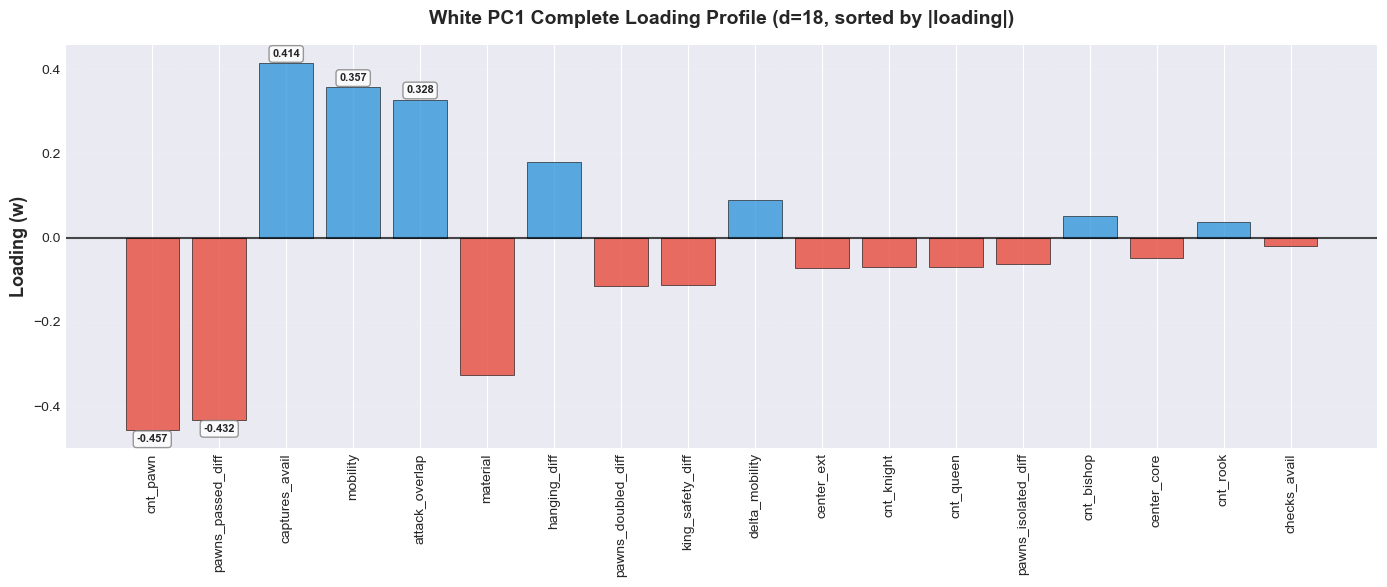


  Top 5 features by |loading|:
    ➖ cnt_pawn                  -0.4568
    ➖ pawns_passed_diff         -0.4320
    ➕ captures_avail            +0.4143
    ➕ mobility                  +0.3570
    ➕ attack_overlap            +0.3276

⚪ WHITE - PC2 Loading Profile
────────────────────────────────────────────────────────────


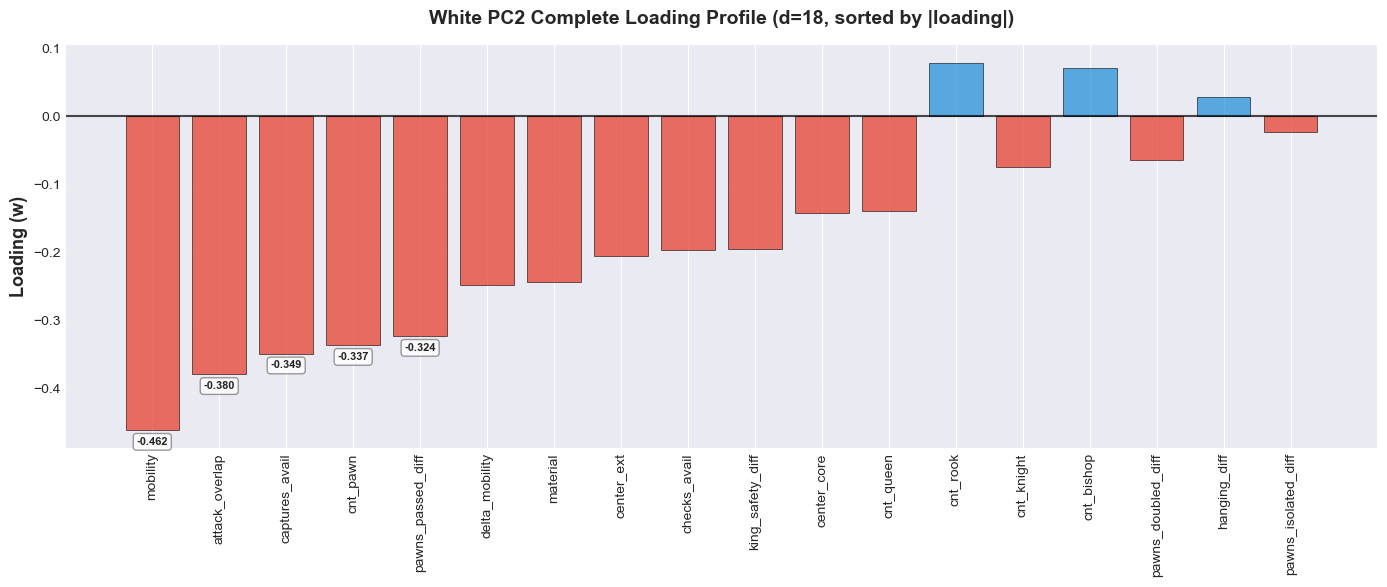


  Top 5 features by |loading|:
    ➖ mobility                  -0.4618
    ➖ attack_overlap            -0.3797
    ➖ captures_avail            -0.3494
    ➖ cnt_pawn                  -0.3368
    ➖ pawns_passed_diff         -0.3235

⚫ BLACK - PC1 Loading Profile
────────────────────────────────────────────────────────────


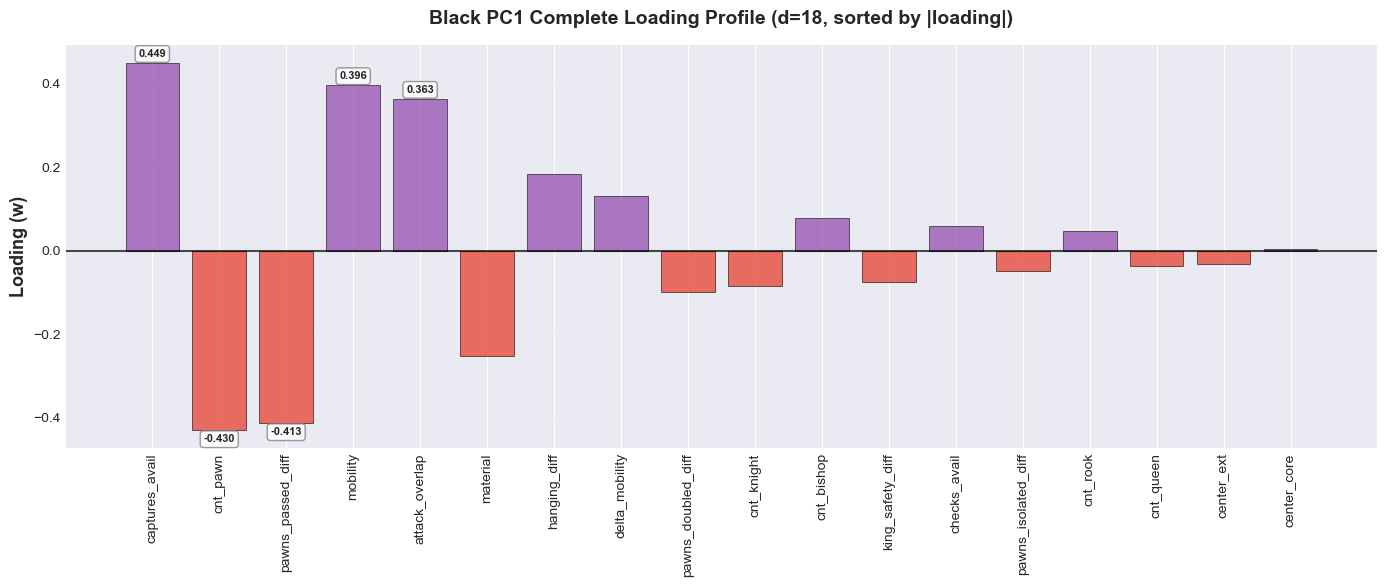


  Top 5 features by |loading|:
    ➕ captures_avail            +0.4491
    ➖ cnt_pawn                  -0.4297
    ➖ pawns_passed_diff         -0.4129
    ➕ mobility                  +0.3960
    ➕ attack_overlap            +0.3632

⚫ BLACK - PC2 Loading Profile
────────────────────────────────────────────────────────────


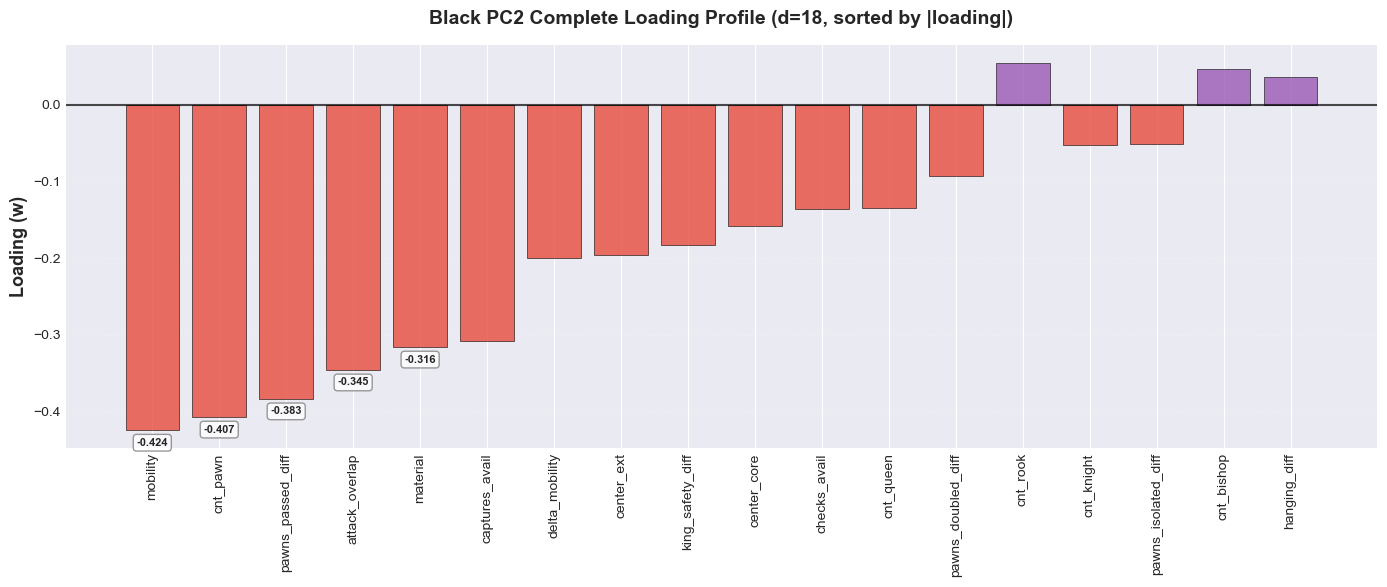


  Top 5 features by |loading|:
    ➖ mobility                  -0.4240
    ➖ cnt_pawn                  -0.4069
    ➖ pawns_passed_diff         -0.3831
    ➖ attack_overlap            -0.3454
    ➖ material                  -0.3156

💾 Saving loading tables...
✅ Saved: loading_profiles/white_loadings_table.csv
✅ Saved: loading_profiles/black_loadings_table.csv

📋 LOADING COMPARISON (White vs Black)

Top 10 features by average PC1 importance:
                    White_PC1  Black_PC1  White_PC2  Black_PC2
cnt_pawn              -0.4568    -0.4297    -0.3368    -0.4069
captures_avail        +0.4143    +0.4491    -0.3494    -0.3084
pawns_passed_diff     -0.4320    -0.4129    -0.3235    -0.3831
mobility              +0.3570    +0.3960    -0.4618    -0.4240
attack_overlap        +0.3276    +0.3632    -0.3797    -0.3454
material              -0.3269    -0.2529    -0.2439    -0.3156
hanging_diff          +0.1786    +0.1841    +0.0276    +0.0364
delta_mobility        +0.0890    +0.1318    -0.2485

In [5]:
# ===== COMPLETE LOADING PROFILES FOR PC1 & PC2 =====
print("\n" + "="*80)
print("📊 GENERATING COMPLETE LOADING PROFILES (PC1 & PC2)")
print("="*80)

# ===== STEP 0: GUARDRAILS =====
print("🔍 Checking prerequisites...")

if 'pca_white' not in globals() or 'pca_black' not in globals():
    raise ValueError("❌ PCA models not found. Need 'pca_white' and 'pca_black'.")

if 'FEATURES' not in globals():
    raise ValueError("❌ FEATURES list not found.")

FEATURES = list(FEATURES)
d = len(FEATURES)

print(f"✅ Found 2 PCA models (White & Black)")
print(f"✅ Features: {d} variables")

# ===== STEP 1: EXTRACT LOADINGS =====
print("\n📐 Extracting loadings from both PCAs...")

# White loadings
loadings_white = pd.DataFrame(
    pca_white.components_.T[:, :2],
    index=FEATURES,
    columns=["PC1", "PC2"]
)

# Black loadings
loadings_black = pd.DataFrame(
    pca_black.components_.T[:, :2],
    index=FEATURES,
    columns=["PC1", "PC2"]
)

print(f"✅ Extracted loadings for White PCA")
print(f"✅ Extracted loadings for Black PCA")

# ===== HELPER FUNCTION: PLOT LOADING PROFILE =====
def plot_loading_profile_improved(series, title, outpath, perspective_color='steelblue'):
    """
    Create publication-quality loading profile barplot
    
    Parameters:
    - series: pd.Series with feature names as index, loadings as values
    - title: plot title
    - outpath: save path
    - perspective_color: color for bars
    """
    # Sort by absolute value (descending)
    s_sorted = series.reindex(series.abs().sort_values(ascending=False).index)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(14, 6))
    
    # Create bars with color based on sign
    colors = [perspective_color if val > 0 else '#e74c3c' for val in s_sorted.values]
    bars = ax.bar(range(len(s_sorted)), s_sorted.values, color=colors, 
                   edgecolor='black', linewidth=0.5, alpha=0.8)
    
    # Zero line
    ax.axhline(0, color='black', linewidth=1.5, linestyle='-', alpha=0.7, zorder=5)
    
    # Styling
    ax.set_xticks(range(len(s_sorted)))
    ax.set_xticklabels(s_sorted.index, rotation=90, ha='center', fontsize=10)
    ax.set_ylabel('Loading (w)', fontsize=13, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.grid(True, alpha=0.25, axis='y', linestyle='--', linewidth=0.5)
    
    # Add value labels for top 5 (by absolute value)
    top_indices = s_sorted.abs().nlargest(5).index
    for i, (name, val) in enumerate(s_sorted.items()):
        if name in top_indices:
            y_offset = 0.01 if val > 0 else -0.01
            va = 'bottom' if val > 0 else 'top'
            ax.text(i, val + y_offset, f'{val:.3f}', 
                   ha='center', va=va, fontsize=8, fontweight='bold',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                            alpha=0.8, edgecolor='gray'))
    
    plt.tight_layout()
    plt.savefig(outpath, dpi=300, bbox_inches='tight')
    plt.savefig(outpath.replace('.png', '.pdf'), bbox_inches='tight')  # Also save PDF
    plt.show()
    
    # Print top 5
    print(f"\n  Top 5 features by |loading|:")
    top5 = s_sorted.head(5)
    for name, val in top5.items():
        sign = '➕' if val > 0 else '➖'
        print(f"    {sign} {name:25s} {val:+.4f}")

# ===== STEP 2-3: GENERATE ALL 4 PROFILES =====
print("\n" + "="*80)
print("📊 CREATING LOADING PROFILES")
print("="*80)

# Create output directory
out_dir = Path("loading_profiles")
out_dir.mkdir(exist_ok=True)

# WHITE - PC1
print("\n⚪ WHITE - PC1 Loading Profile")
print("─" * 60)
plot_loading_profile_improved(
    loadings_white["PC1"],
    f"White PC1 Complete Loading Profile (d={d}, sorted by |loading|)",
    str(out_dir / "white_pc1_loading_profile.png"),
    perspective_color='#3498db'  # Blue
)

# WHITE - PC2
print("\n⚪ WHITE - PC2 Loading Profile")
print("─" * 60)
plot_loading_profile_improved(
    loadings_white["PC2"],
    f"White PC2 Complete Loading Profile (d={d}, sorted by |loading|)",
    str(out_dir / "white_pc2_loading_profile.png"),
    perspective_color='#3498db'  # Blue
)

# BLACK - PC1
print("\n⚫ BLACK - PC1 Loading Profile")
print("─" * 60)
plot_loading_profile_improved(
    loadings_black["PC1"],
    f"Black PC1 Complete Loading Profile (d={d}, sorted by |loading|)",
    str(out_dir / "black_pc1_loading_profile.png"),
    perspective_color='#9b59b6'  # Purple
)

# BLACK - PC2
print("\n⚫ BLACK - PC2 Loading Profile")
print("─" * 60)
plot_loading_profile_improved(
    loadings_black["PC2"],
    f"Black PC2 Complete Loading Profile (d={d}, sorted by |loading|)",
    str(out_dir / "black_pc2_loading_profile.png"),
    perspective_color='#9b59b6'  # Purple
)

# ===== SAVE LOADING TABLES (CSV) =====
print("\n💾 Saving loading tables...")

# White loadings (sorted by PC1 absolute value)
loadings_white_sorted = loadings_white.reindex(
    loadings_white['PC1'].abs().sort_values(ascending=False).index
)
loadings_white_sorted.to_csv(out_dir / "white_loadings_table.csv")

# Black loadings (sorted by PC1 absolute value)
loadings_black_sorted = loadings_black.reindex(
    loadings_black['PC1'].abs().sort_values(ascending=False).index
)
loadings_black_sorted.to_csv(out_dir / "black_loadings_table.csv")

print(f"✅ Saved: {out_dir}/white_loadings_table.csv")
print(f"✅ Saved: {out_dir}/black_loadings_table.csv")

# ===== COMPARISON TABLE =====
print("\n" + "="*80)
print("📋 LOADING COMPARISON (White vs Black)")
print("="*80)

comparison = pd.DataFrame({
    'White_PC1': loadings_white['PC1'],
    'Black_PC1': loadings_black['PC1'],
    'White_PC2': loadings_white['PC2'],
    'Black_PC2': loadings_black['PC2']
})

# Sort by average absolute PC1 loading
comparison['avg_abs_pc1'] = (comparison['White_PC1'].abs() + comparison['Black_PC1'].abs()) / 2
comparison = comparison.sort_values('avg_abs_pc1', ascending=False)
comparison = comparison.drop('avg_abs_pc1', axis=1)

print("\nTop 10 features by average PC1 importance:")
print(comparison.head(10).to_string(float_format=lambda x: f'{x:+.4f}'))

# Save comparison
comparison.to_csv(out_dir / "loadings_comparison.csv")
print(f"\n💾 Saved: {out_dir}/loadings_comparison.csv")

# ===== FINAL SUMMARY =====
print("\n" + "="*80)
print("✅ COMPLETE LOADING PROFILES GENERATED")
print("="*80)
print(f"\n📁 Files saved in: {out_dir.absolute()}")
print("\n📋 Generated files:")
print("   🖼️  PNG (high-res):")
print("      • white_pc1_loading_profile.png")
print("      • white_pc2_loading_profile.png")
print("      • black_pc1_loading_profile.png")
print("      • black_pc2_loading_profile.png")
print("   📄 PDF (vector):")
print("      • white_pc1_loading_profile.pdf")
print("      • white_pc2_loading_profile.pdf")
print("      • black_pc1_loading_profile.pdf")
print("      • black_pc2_loading_profile.pdf")
print("   📊 CSV tables:")
print("      • white_loadings_table.csv")
print("      • black_loadings_table.csv")
print("      • loadings_comparison.csv")
print("\n💡 Ready for LaTeX inclusion! Use PDF for vector graphics or PNG for compatibility.")
print("="*80)